<div align="center">

<a href="https://colab.research.google.com/github/zahran-rzq/DSEC_ets_object_detection/blob/arena/e1293095-dsec-ets-object-detection/DSEC_Security_Camera_ETS.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" height="46"></a>

**Klik tombol di atas untuk membuka notebook ini di Google Colab**
*(atau langsung: **File → Open notebook → tab GitHub → `zahran-rzq/DSEC_ets_object_detection`**)*

</div>

---

# 🛡️ SecureVision — Aplikasi Kamera Keamanan Berbasis Deep Learning
### Deteksi Real-Time: **person · car · truck · motorbike** + Auto-Snapshot & Auto-Recording
**Mata kuliah:** Deep Learning for Security (DSEC) · **Soal 2 — ETS**

---

## 🚀 Cara pakai saat ETS (URUTAN CEPAT — total ±15 menit)

| Langkah | Aksi | Perkiraan |
|---|---|---|
| 1 | `Runtime → Change runtime type → **T4 GPU** → Save` | 10 detik |
| 2 | `Runtime → Run all` | ✅ disarankan |
| 3 | Tunggu sel **Bagian 3 (Training smoke-test)** selesai | ±3 menit |
| 4 | Buka **Bagian 4** untuk angka mAP / Precision / Recall | langsung |
| 5 | Buka **Bagian 5** untuk demo **webcam live** di browser | 1 menit |
| 6 | **Bagian 6** → unduh `best.pt` + laporan untuk dikumpulkan | 1 menit |

> **Tidak punya dataset?** Tidak masalah. Notebook ini **langsung jalan** dengan
> bobot pre-trained COCO (`yolo11n.pt`) + filter kelas. Bagian training
> memakai `coco8.yaml` (8 gambar) hanya sebagai **smoke test** agar seluruh
> pipeline terbukti berjalan; ganti dengan datasetmu di `Bagian 2` bila perlu.

> **Boleh lompat-lompat sel.** Setiap sel kode sudah dilengkapi *guard* yang
> otomatis mengisi nilai default (`SKIP_TRAINING`, `DATA_YAML`, `IMG_SIZE`,
> `TARGET_IDS`, `model`, gambar contoh, fungsi metrik, dll.) bila sel
> konfigurasi belum dijalankan — jadi **tidak akan muncul `NameError`**.
> Untuk mengubah nilainya, jalankan sel **1.1** (konfigurasi model) dan
> **2.1** (konfigurasi dataset/training).

---

## 📋 Daftar isi
0. Environment & instalasi
1. **Konfigurasi model pre-trained** (arsitektur + filter 4 kelas)
2. Dataset & fine-tuning (opsional)
3. **Training**
4. **Evaluasi** — IoU, Precision, Recall, AP, mAP (implementasi manual + Ultralytics)
5. **Demo webcam live** di Colab
6. Ekspor & unduh artefak
7. Cheat-sheet jawaban lisan + troubleshooting

---
## 0) Environment & instalasi

In [1]:
# @title 0.1 Cek environment  ▶ jalankan ini DULU
import os, sys, platform, subprocess
from pathlib import Path

print("=" * 58)
print("  CEK ENVIRONMENT")
print("=" * 58)
print("Python      :", sys.version.split()[0])
print("Platform    :", platform.platform())

try:
    import torch
    print("PyTorch     :", torch.__version__)
    print("CUDA ready  :", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU         :", torch.cuda.get_device_name(0))
        print("VRAM        :", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")
    else:
        print("⚠️  Tidak ada GPU. Masih bisa jalan (CPU), tapi training akan lambat.")
        print("   -> Runtime > Change runtime type > T4 GPU")
except ImportError:
    print("PyTorch belum terpasang (akan diinstall di sel berikutnya)")

try:
    import ultralytics
    print("ultralytics :", ultralytics.__version__)
except ImportError:
    print("ultralytics : belum terpasang")

try:
    from google.colab import drive
    IN_COLAB = True
    print("Lingkungan  : Google Colab ✅")
except ImportError:
    IN_COLAB = False
    print("Lingkungan  : lokal / Jupyter (bukan Colab)")

  CEK ENVIRONMENT
Python      : 3.13.16
Platform    : Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch     : 2.11.0+cu130
CUDA ready  : True
GPU         : Tesla T4
VRAM        : 15.6 GB
ultralytics : 8.4.189
Lingkungan  : Google Colab ✅


In [2]:
# @title 0.2 Instalasi dependensi
import subprocess, sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade",
                "ultralytics>=8.3.0", "opencv-python-headless", "matplotlib",
                "pandas", "pillow", "seaborn"], check=False)

import ultralytics, cv2, torch
print(f"✅ ultralytics {ultralytics.__version__} | opencv {cv2.__version__} | torch {torch.__version__}")

✅ ultralytics 8.4.189 | opencv 4.14.0 | torch 2.11.0+cu130


In [3]:
# @title 0.3 (Opsional) Hubungkan Google Drive — agar hasil training tidak hilang
USE_DRIVE = True   # <-- ubah ke False kalau tidak ingin mount Drive

WORKDIR = Path("/content/securevision")
WORKDIR.mkdir(parents=True, exist_ok=True)

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        WORKDIR = Path("/content/drive/MyDrive/securevision")
        WORKDIR.mkdir(parents=True, exist_ok=True)
        print("✅ Drive terhubung. Output disimpan di:", WORKDIR)
    except Exception as e:
        print("⚠️  Drive gagal dimount, pakai /content:", e)
        WORKDIR = Path("/content/securevision")
        WORKDIR.mkdir(parents=True, exist_ok=True)
else:
    print("Output disimpan di:", WORKDIR)

os.chdir(WORKDIR)
print("Working directory:", Path.cwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Drive terhubung. Output disimpan di: /content/drive/MyDrive/securevision
Working directory: /content/drive/MyDrive/securevision


---
# 1) Konfigurasi Model Pre-Trained

## 1.1 Pilihan arsitektur

| Kriteria | Pilihan | Alasan |
|---|---|---|
| Keluarga model | **YOLO (You Only Look Once)** — `YOLOv11n` / `YOLOv8n` | *Single-stage detector*: satu kali *forward pass* menghasilkan seluruh kotak + kelas → latensi rendah, cocok untuk video real-time (30 FPS di CPU, >100 FPS di GPU T4) |
| Varian | **nano (`n`)** | 2,6 M parameter, ~6,5 GFLOPs, file bobot 5 MB → ringan, bisa dipasang di laptop/PC tanpa GPU saat demo |
| Alternatif | `s`/`m` | Dipakai kalau GPU tersedia dan dibutuhkan akurasi lebih tinggi |
| Pre-training | **COCO** (80 kelas, 118 ribu gambar) | Sudah memuat 4 kelas target: `person(0)`, `car(2)`, `motorcycle(3)`, `truck(7)` → **tanpa training pun aplikasi langsung berfungsi** |

### Mengapa bukan two-stage (Faster R-CNN / R-CNN)?
Two-stage menghasilkan *Region Proposal* dulu baru klasifikasi → akurat tetapi
~5–10× lebih lambat (5–7 FPS). Untuk kamera keamanan yang harus memberi
peringatan **seketika**, latensi YOLO (≈10–25 ms/frame) jauh lebih tepat.

### Mengapa bukan klasifikasi + sliding window?
Tidak bisa memberi **lokalisasi** (koordinat kotak) dan tidak bisa menangani
banyak objek sekaligus dalam satu frame.

## 1.2 Cara membatasi model HANYA ke 4 kelas target

Ada **3 lapisan filter**, diurutkan dari yang paling efisien:

1. **Filter di level model (`classes=[0,2,3,7]`)**
   Ultralytics membuang logit kelas lain *sebelum* NMS.
   → paling hemat komputasi, dan mencegah *false positive* dari kelas mirip
   (mis. `bus`, `bicycle`, `dog`) ikut diproses.
2. **Threshold confidence per-kelas** — `person` dibuat lebih sensitif (0.30)
   karena menyangkut keselamatan, `car`/`truck` lebih ketat (0.40).
3. **Filter di level aplikasi** — luas kotak minimum (buang noise jauh) dan
   ROI/polygon (mis. hanya area pintu masuk).

In [4]:
# @title 1.1 Konfigurasi terpusat — UBAH DI SINI SAJA
from dataclasses import dataclass, field, asdict
from pathlib import Path
import json

# ---------------------------------------------------------------- kelas ---
# COCO: 80 kelas. Yang kita pakai hanya 4.
# CATATAN: soal menyebut "motorbike"; di COCO bernama "motorcycle" (id 3).
#          Keduanya OBJEK YANG SAMA -> dipetakan ke id 3.
COCO_CLASS_IDS = {
    "person":     0,
    "car":        2,
    "motorbike":  3,   # COCO: "motorcycle"
    "truck":      7,
}

TARGET_CLASSES  = ["person", "car", "truck", "motorbike"]
TARGET_IDS      = sorted(COCO_CLASS_IDS[c] for c in TARGET_CLASSES)

# Threshold confidence per kelas (keamanan = person paling sensitif)
PER_CLASS_CONF  = {"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35}

# Warna untuk visualisasi (hex)
CLASS_COLORS    = {"person": "#20A840", "car": "#1A76E8",
                   "truck": "#D63636", "motorbike": "#E05C18"}

# ---------------------------------------------------------------- model ---
WEIGHTS = "yolo11n.pt"   # ganti: yolov8n.pt | yolo11s.pt | path/best.pt
IMG_SIZE = 640           # 640 = standar; 416 = lebih cepat; 1280 = lebih teliti
CONF     = 0.35          # ambang keyakinan global
IOU_NMS  = 0.45          # ambang IoU untuk Non-Maximum Suppression
DEVICE   = 0 if torch.cuda.is_available() else "cpu"

print("=" * 66)
print("  KONFIGURASI MODEL PRE-TRAINED")
print("=" * 66)
print(f"Arsitektur        : YOLO (Ultralytics) — {WEIGHTS}")
print(f"Pre-training      : COCO (80 kelas)")
print(f"Input             : {IMG_SIZE} x {IMG_SIZE} (letterbox)")
print(f"Device            : {DEVICE}")
print("-" * 66)
print(f"Kelas target      : {TARGET_CLASSES}")
print(f"ID kelas COCO     : {TARGET_IDS}   <-- diteruskan ke model(classes=[...])")
print(f"Conf per kelas    : {PER_CLASS_CONF}")
print("-" * 66)
print("Kelas COCO yang DIBUANG (contoh): bus(5), bicycle(1), dog(16),")
print("chair(56), traffic light(9), stop sign(11), ... dst (76 kelas lain)")
print("=" * 66)

  KONFIGURASI MODEL PRE-TRAINED
Arsitektur        : YOLO (Ultralytics) — yolo11n.pt
Pre-training      : COCO (80 kelas)
Input             : 640 x 640 (letterbox)
Device            : 0
------------------------------------------------------------------
Kelas target      : ['person', 'car', 'truck', 'motorbike']
ID kelas COCO     : [0, 2, 3, 7]   <-- diteruskan ke model(classes=[...])
Conf per kelas    : {'person': 0.3, 'car': 0.4, 'truck': 0.4, 'motorbike': 0.35}
------------------------------------------------------------------
Kelas COCO yang DIBUANG (contoh): bus(5), bicycle(1), dog(16),
chair(56), traffic light(9), stop sign(11), ... dst (76 kelas lain)


In [5]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

# @title 1.2 Muat model + demonstrasi "tanpa filter" vs "dengan filter"
from ultralytics import YOLO
import urllib.request, numpy as np, cv2
from PIL import Image
import matplotlib.pyplot as plt

model = YOLO(WEIGHTS)           # bobot diunduh otomatis bila belum ada
model.info(verbose=False) if hasattr(model, "info") else None

# --- ambil gambar contoh (butuh internet; ganti dengan filemu jika offline) ---
SAMPLE = Path("sample.jpg")
if not SAMPLE.exists():
    for url in ["https://ultralytics.com/images/bus.jpg",
                "https://github.com/ultralytics/assets/releases/download/v0.0.0/bus.jpg"]:
        try:
            urllib.request.urlretrieve(url, SAMPLE)
            print("Gambar contoh diunduh:", url); break
        except Exception:
            continue
if not SAMPLE.exists():
    # fallback: gambar sintetis bila Colab tanpa internet
    Image.new("RGB", (640, 480), (60, 60, 60)).save(SAMPLE)
    print("⚠️  Pakai gambar sintetis (tidak ada koneksi)")

img_bgr = cv2.imread(str(SAMPLE))
print("Ukuran gambar:", img_bgr.shape[1], "x", img_bgr.shape[0])

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Ukuran gambar: 810 x 1080


--- TANPA filter kelas (80 kelas COCO) ---
  jumlah deteksi : 5
     person         4
     bus            1

--- DENGAN filter kelas ['person', 'car', 'truck', 'motorbike'] ---
  jumlah deteksi : 4
     person         4

✅ 1 deteksi non-target dibuang di level model.


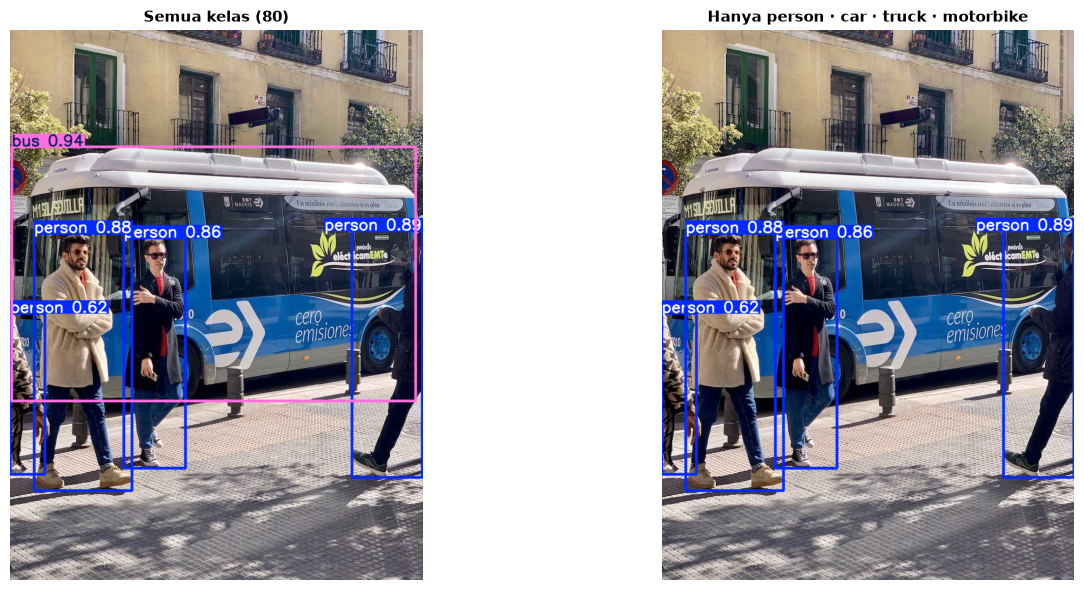

In [6]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------


# --- helper: pastikan gambar contoh tersedia --------------------------------
try:
    img_bgr
except NameError:
    import cv2 as _cv
    import urllib.request as _u
    import numpy as _np
    SAMPLE = Path("sample.jpg")
    if not SAMPLE.exists():
        try:
            _u.urlretrieve("https://ultralytics.com/images/bus.jpg", str(SAMPLE))
        except Exception:
            _cv.imwrite(str(SAMPLE), _np.full((480, 640, 3), 60, _np.uint8))
    img_bgr = _cv.imread(str(SAMPLE))
    print("📌 Gambar contoh dimuat otomatis:", SAMPLE)
# --- akhir helper gambar ------------------------------------------------------

# @title 1.3 Jalankan inferensi: SEMUA kelas vs HANYA 4 kelas target
def run(classes=None, conf=CONF):
    return model.predict(img_bgr, imgsz=IMG_SIZE, conf=conf, iou=IOU_NMS,
                         classes=classes, device=DEVICE, verbose=False)[0]

r_all = run(classes=None)        # 80 kelas
r_tgt = run(classes=TARGET_IDS)  # hanya 4 kelas  ✅

def summarize(r, title):
    names = r.names
    counts = {}
    for b in r.boxes:
        counts[names[int(b.cls)]] = counts.get(names[int(b.cls)], 0) + 1
    print(f"--- {title} ---")
    print(f"  jumlah deteksi : {len(r.boxes)}")
    for k, v in sorted(counts.items(), key=lambda x: -x[1]):
        print(f"     {k:<14} {v}")
    print()
    return counts

c_all = summarize(r_all, "TANPA filter kelas (80 kelas COCO)")
c_tgt = summarize(r_tgt, f"DENGAN filter kelas {TARGET_CLASSES}")

n_removed = len(r_all.boxes) - len(r_tgt.boxes)
print(f"✅ {n_removed} deteksi non-target dibuang di level model.")

# --- tampilkan berdampingan ---
def plot(r, ax, title):
    im = r.plot()[:, :, ::-1]          # BGR -> RGB
    ax.imshow(im); ax.set_title(title, fontsize=11, fontweight="bold"); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot(r_all, axes[0], "Semua kelas (80)")
plot(r_tgt, axes[1], "Hanya person · car · truck · motorbike")
plt.tight_layout(); plt.show()

In [7]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------


# --- helper: pastikan gambar contoh tersedia --------------------------------
try:
    img_bgr
except NameError:
    import cv2 as _cv
    import urllib.request as _u
    import numpy as _np
    SAMPLE = Path("sample.jpg")
    if not SAMPLE.exists():
        try:
            _u.urlretrieve("https://ultralytics.com/images/bus.jpg", str(SAMPLE))
        except Exception:
            _cv.imwrite(str(SAMPLE), _np.full((480, 640, 3), 60, _np.uint8))
    img_bgr = _cv.imread(str(SAMPLE))
    print("📌 Gambar contoh dimuat otomatis:", SAMPLE)
# --- akhir helper gambar ------------------------------------------------------

# @title 1.4 Implementasi filter kelas + confidence per-kelas di level aplikasi
def detect_targets(frame_bgr, model, classes=TARGET_IDS, per_class_conf=PER_CLASS_CONF,
                   conf=CONF, iou=IOU_NMS, imgsz=IMG_SIZE, min_area=900):
    '''
    "Satu fungsi pemanggilan model" yang dipakai aplikasi desktop.

    Langkah: letterbox -> forward pass -> NMS -> filter kelas ->
             filter conf per-kelas -> filter luas kotak.
    Return: list of dict {name, conf, box:[x1,y1,x2,y2], area}
    '''
    conf_min = min([per_class_conf.get(c, conf) for c in per_class_conf] + [conf])
    res = model.predict(frame_bgr, imgsz=imgsz, conf=conf_min, iou=iou,
                        classes=classes, device=DEVICE, verbose=False)[0]
    id2name = {v: k for k, v in COCO_CLASS_IDS.items()}
    out = []
    for b in res.boxes:
        cid  = int(b.cls)
        name = id2name.get(cid)
        if name is None:                                   # lapis 1: kelas
            continue
        c = float(b.conf)
        if c < per_class_conf.get(name, conf):             # lapis 2: conf/kelas
            continue
        x1, y1, x2, y2 = map(float, b.xyxy[0])
        area = (x2 - x1) * (y2 - y1)
        if area < min_area:                                # lapis 3: ukuran
            continue
        out.append({"name": name, "conf": round(c, 3),
                    "box": [round(v) for v in (x1, y1, x2, y2)], "area": round(area)})
    return out

dets = detect_targets(img_bgr, model)
print("Hasil akhir yang dipakai aplikasi:")
for d in dets:
    print(f"  {d['name']:<10} conf={d['conf']:.2f}  box={d['box']}  area={d['area']}")
print(f"Total: {len(dets)} objek target")

Hasil akhir yang dipakai aplikasi:
  person     conf=0.89  box=[671, 395, 810, 879]  area=67159
  person     conf=0.88  box=[47, 400, 239, 904]  area=96836
  person     conf=0.86  box=[223, 409, 344, 860]  area=54846
  person     conf=0.62  box=[0, 556, 69, 872]  area=21781
Total: 4 objek target


---
# 2) Dataset & Persiapan Fine-Tuning *(opsional)*

Model pre-trained COCO **sudah bisa dipakai langsung**. Fine-tuning hanya
perlu kalau kondisi kamera berbeda jauh dari COCO (mis. kamera CCTV
*top-down*, malam hari, atau sudut pandang tidak lazim).

Pilih **salah satu** sumber data di bawah:

| Opsi | Kapan dipakai | Cara |
|---|---|---|
| **A. `coco8.yaml`** (default) | Cuma mau membuktikan pipeline training jalan | Sudah tersedia di dalam `ultralytics`, 8 gambar, selesai < 1 menit |
| **B. Roboflow** | Punya/sudah menemukan dataset publik siap pakai | Isi `ROBOFLOW_API_KEY` + URL |
| **C. ZIP dari Drive** | Dataset sudah kamu miliki (format YOLO) | Upload → set path |
| **D. Lewati** | Tidak perlu training | Set `SKIP_TRAINING = True` |

### Catatan penting: meremap label ke 4 kelas
Dataset publik biasanya berlabel 80 kelas COCO. Supaya **model benar-benar
hanya mengenal 4 kelas** (bukan sekadar difilter saat inference), label harus
di-remap: `person→0, car→1, truck→2, motorbike→3` dan baris kelas lain
**dihapus** dari file `.txt`. Fungsi `remap_dataset_to_targets()` di bawah
melakukan hal itu secara otomatis.

In [8]:
# @title 2.1 Pilih sumber dataset
SKIP_TRAINING = False        # True = lewati Bagian 2 & 3, langsung ke Bagian 4
DATASET_OPTION = "A"         # "A"=coco8  |  "B"=Roboflow  |  "C"=ZIP di Drive

# ---- Opsi B: Roboflow -----------------------------------------------------
ROBOFLOW_API_KEY = ""        # contoh: "AbCdEf123456"
ROBOFLOW_WORKSPACE = ""
ROBOFLOW_PROJECT   = ""
ROBOFLOW_VERSION   = 1

# ---- Opsi C: ZIP dataset format YOLO di Drive -----------------------------
ZIP_PATH = "/content/drive/MyDrive/dataset_security.zip"

# ---- Hyperparameter training ---------------------------------------------
EPOCHS     = 20     # smoke test: 3-5  |  hasil serius: 50-100
BATCH      = 16     # T4(16GB): 16  |  CPU / VRAM kecil: 8 atau 4
PATIENCE   = 10     # early stopping
FREEZE     = 10     # bekukan 10 layer backbone teratas (transfer learning cepat)

print("Opsi dataset:", DATASET_OPTION, "| epochs:", EPOCHS, "| batch:", BATCH)

Opsi dataset: A | epochs: 20 | batch: 16


In [9]:
# @title 2.2 Fungsi: remap dataset YOLO -> hanya 4 kelas target
import shutil, random
from pathlib import Path
from tqdm.auto import tqdm

# Urutan kelas model custom (indeks baru)
CUSTOM_CLASSES = ["person", "car", "truck", "motorbike"]     # index 0,1,2,3
COCO_TO_CUSTOM = {"person": 0, "car": 1, "truck": 2, "motorbike": 3, "motorcycle": 3}

def remap_dataset_to_targets(src_root: Path, dst_root: Path,
                             splits=("train", "valid", "val", "test")) -> Path:
    '''
    Salin dataset format YOLO (images/ + labels/) dengan hanya menyisipkan
    4 kelas target dan me-remap id-nya ke 0..3.
    '''
    src_root, dst_root = Path(src_root), Path(dst_root)
    if dst_root.exists():
        shutil.rmtree(dst_root)
    stats = {}
    for split in splits:
        img_dirs = [p for p in [src_root / split / "images",
                                src_root / "images" / split] if p.is_dir()]
        lbl_dirs = [p for p in [src_root / split / "labels",
                                src_root / "labels" / split] if p.is_dir()]
        if not img_dirs or not lbl_dirs:
            continue
        img_dir, lbl_dir = img_dirs[0], lbl_dirs[0]
        (dst_root / split / "images").mkdir(parents=True, exist_ok=True)
        (dst_root / split / "labels").mkdir(parents=True, exist_ok=True)

        kept = dropped = 0
        for lbl in tqdm(sorted(lbl_dir.glob("*.txt")), desc=f"remap {split}", leave=False):
            img = next((img_dir / (lbl.stem + e)
                        for e in (".jpg", ".png", ".jpeg", ".bmp")
                        if (img_dir / (lbl.stem + e)).exists()), None)
            if img is None:
                continue
            new_lines = []
            for line in lbl.read_text().splitlines():
                p = line.split()
                if not p:
                    continue
                try:
                    old_id = int(p[0])
                except ValueError:
                    continue
                # file label COCO-format: id = id COCO
                name = {0: "person", 2: "car", 7: "truck", 3: "motorbike"}.get(old_id)
                if name is None:
                    dropped += 1
                    continue
                new_lines.append(" ".join([str(COCO_TO_CUSTOM[name])] + p[1:]))
                kept += 1
            if new_lines:
                (dst_root / split / "labels" / lbl.name).write_text("\n".join(new_lines))
                shutil.copy2(img, dst_root / split / "images" / img.name)
        stats[split] = {"objek_disimpan": kept, "objek_dibuang": dropped,
                        "gambar": len(list((dst_root / split / "images").glob("*")))}
    print(json.dumps(stats, indent=2))
    return dst_root

def write_data_yaml(root: Path, class_names=CUSTOM_CLASSES) -> Path:
    root = Path(root)
    yaml_txt = [f"path: {root.resolve()}", "train: train/images", "val: valid/images"]
    if (root / "test" / "images").exists():
        yaml_txt.append("test: test/images")
    yaml_txt.append("names:")
    for i, n in enumerate(class_names):
        yaml_txt.append(f"  {i}: {n}")
    p = root / "data.yaml"
    p.write_text("\n".join(yaml_txt) + "\n")
    print(p.read_text())
    return p

In [10]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

# @title 2.3 Siapkan dataset sesuai opsi yang dipilih
DATA_YAML = None

if SKIP_TRAINING:
    print("⏭️  Training dilewati (SKIP_TRAINING=True). Lanjut ke Bagian 4.")

elif DATASET_OPTION == "A":
    # coco8: dataset mini bawaan ultralytics untuk smoke test
    DATA_YAML = "coco8.yaml"
    print("Memakai coco8.yaml (8 gambar, 80 kelas) — SMOKE TEST pipeline.")
    print("Untuk hasil nyata, ganti DATASET_OPTION ke 'B' atau 'C'.")

elif DATASET_OPTION == "B":
    assert ROBOFLOW_API_KEY, "Isi ROBOFLOW_API_KEY di sel 2.1!"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "roboflow"], check=False)
    from roboflow import Roboflow
    rf    = Roboflow(api_key=ROBOFLOW_API_KEY)
    proj  = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT)
    ds    = proj.version(ROBOFLOW_VERSION).download("yolov11")
    raw   = Path(ds.location)
    dst   = WORKDIR / "datasets" / "security_4class"
    remap_dataset_to_targets(raw, dst)
    DATA_YAML = write_data_yaml(dst)

elif DATASET_OPTION == "C":
    assert Path(ZIP_PATH).exists(), f"ZIP tidak ditemukan: {ZIP_PATH}"
    raw = WORKDIR / "datasets" / "raw"
    raw.mkdir(parents=True, exist_ok=True)
    shutil.unpack_archive(ZIP_PATH, raw)
    dst = WORKDIR / "datasets" / "security_4class"
    remap_dataset_to_targets(raw, dst)
    DATA_YAML = write_data_yaml(dst)

print("\nDATA_YAML =", DATA_YAML)

Memakai coco8.yaml (8 gambar, 80 kelas) — SMOKE TEST pipeline.
Untuk hasil nyata, ganti DATASET_OPTION ke 'B' atau 'C'.

DATA_YAML = coco8.yaml


---
# 3) Training (Fine-Tuning)

**Transfer learning**: bobot COCO dipakai sebagai titik awal, lalu
di-*fine-tune* pada dataset keamanan. Manfaatnya: konvergen jauh lebih cepat
dan tetap akurat walau dataset kecil (ratusan gambar sudah cukup).

Strategi yang dipakai di sini:
* `pretrained=True` → mulai dari bobot COCO.
* `freeze=10` → 10 layer backbone teratas dibekukan (fitur tepi/tekstur umum
  tidak perlu diubah) → lebih cepat, mencegah *overfitting* pada dataset kecil.
* Augmentasi bawaan Ultralytics (`hsv_h`, `flipud`, `fliplr`, `mosaic`,
  `scale`, `translate`) → tahan terhadap variasi cahaya & sudut kamera CCTV.
* `patience=10` → *early stopping* agar tidak membuang waktu.

In [11]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

# @title 3.1 Jalankan training
if SKIP_TRAINING:
    print("⏭️  dilewati")
else:
    if DATA_YAML is None:
        DATA_YAML = "coco8.yaml"
        print("📌 DATA_YAML belum diisi (sel 2.3 belum dijalankan) -> pakai coco8.yaml")
    train_args = dict(
        data=DATA_YAML,
        epochs=EPOCHS,
        imgsz=IMG_SIZE,
        batch=BATCH,
        device=DEVICE,
        project=str(WORKDIR / "runs" / "detect"),
        name="train",
        exist_ok=True,
        pretrained=True,
        optimizer="auto",
        patience=PATIENCE,
        cos_lr=True,
        plots=True,
        verbose=True,
    )
    # freeze hanya masuk akal untuk model yang benar-benar di-fine-tune
    if FREEZE and DATASET_OPTION in ("B", "C"):
        train_args["freeze"] = FREEZE

    results = model.train(**train_args)
    print("\n✅ Training selesai.")
    print("Bobot terbaik:", WORKDIR / "runs/detect/train/weights/best.pt")

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mas


📊 results.png


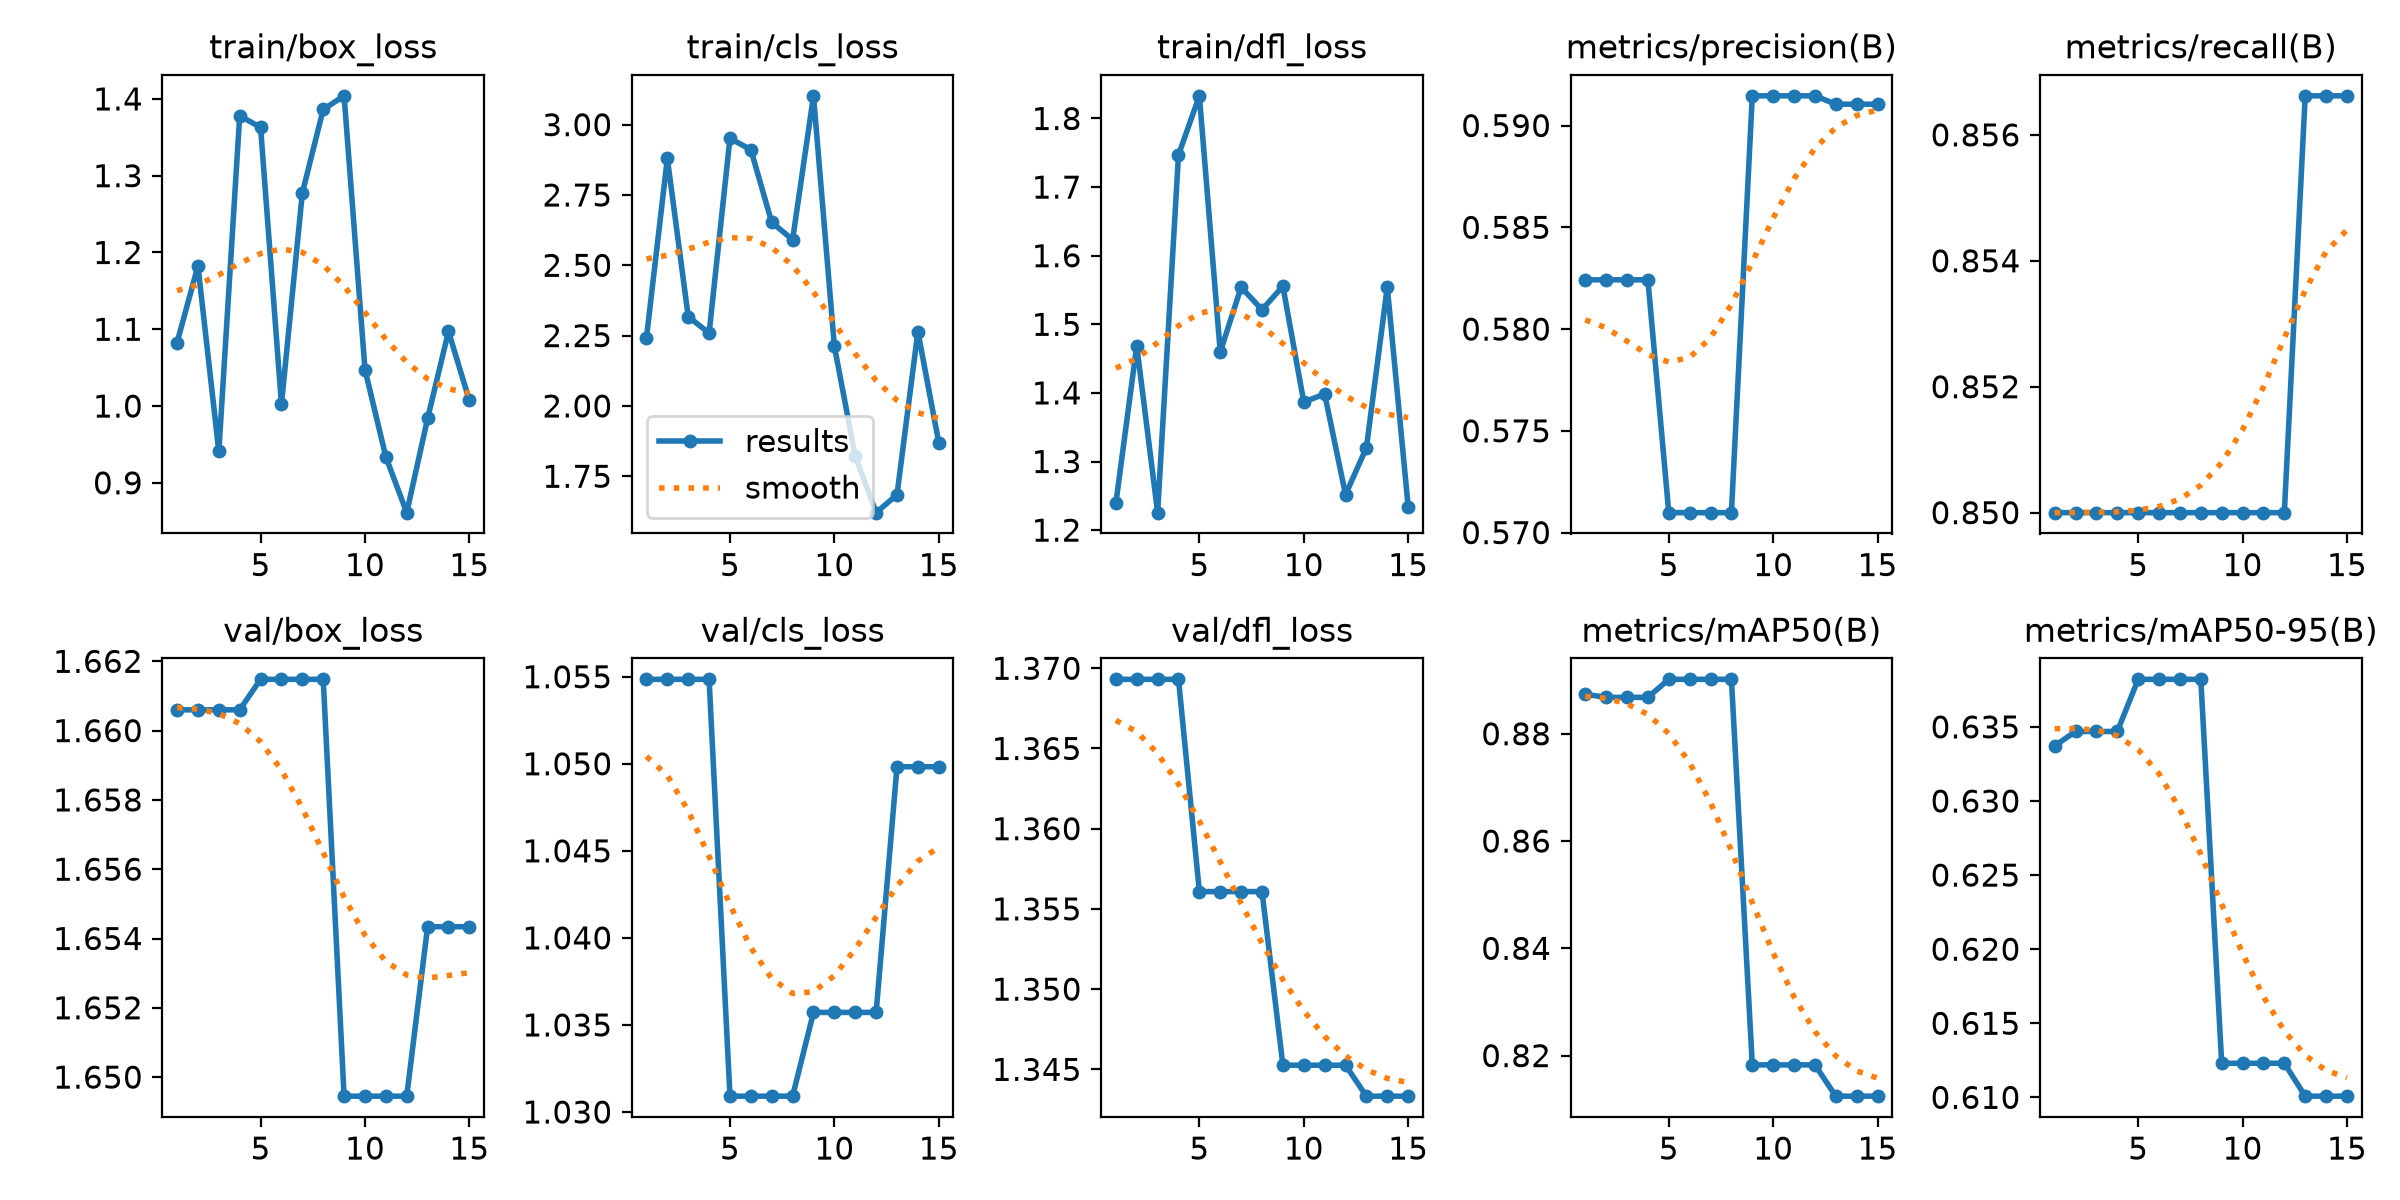


📊 confusion_matrix.png


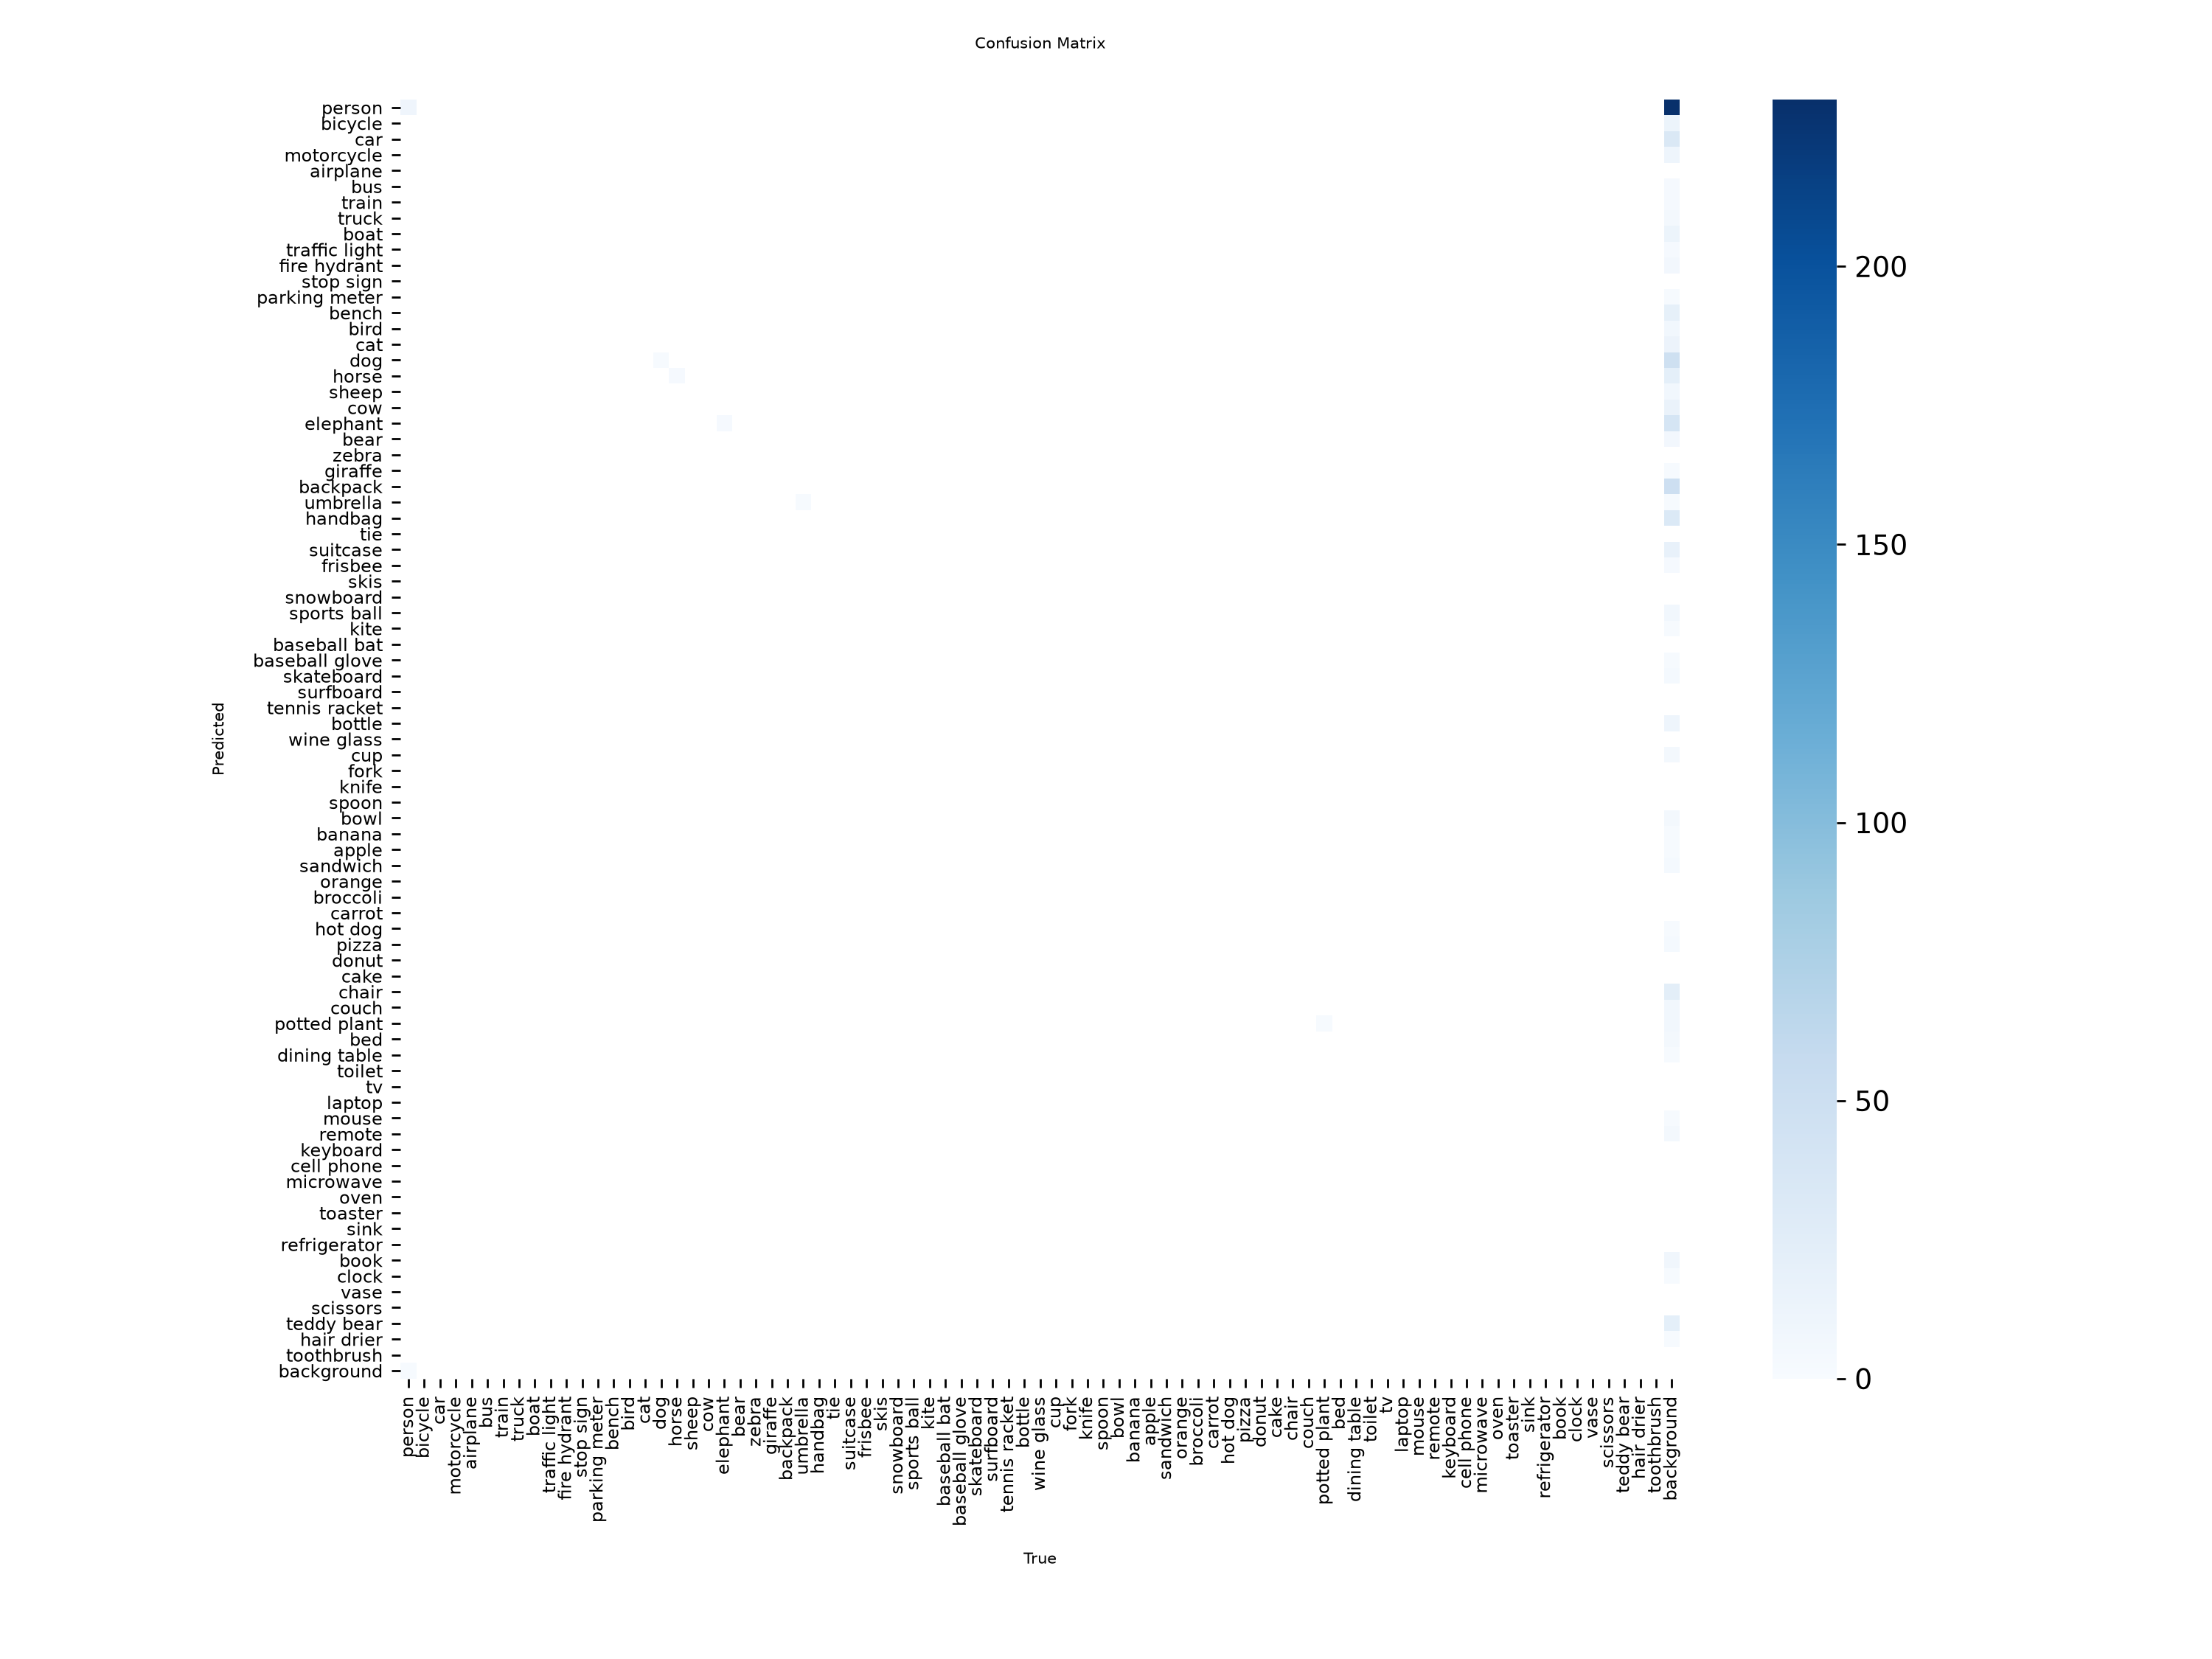


📊 train_batch0.jpg


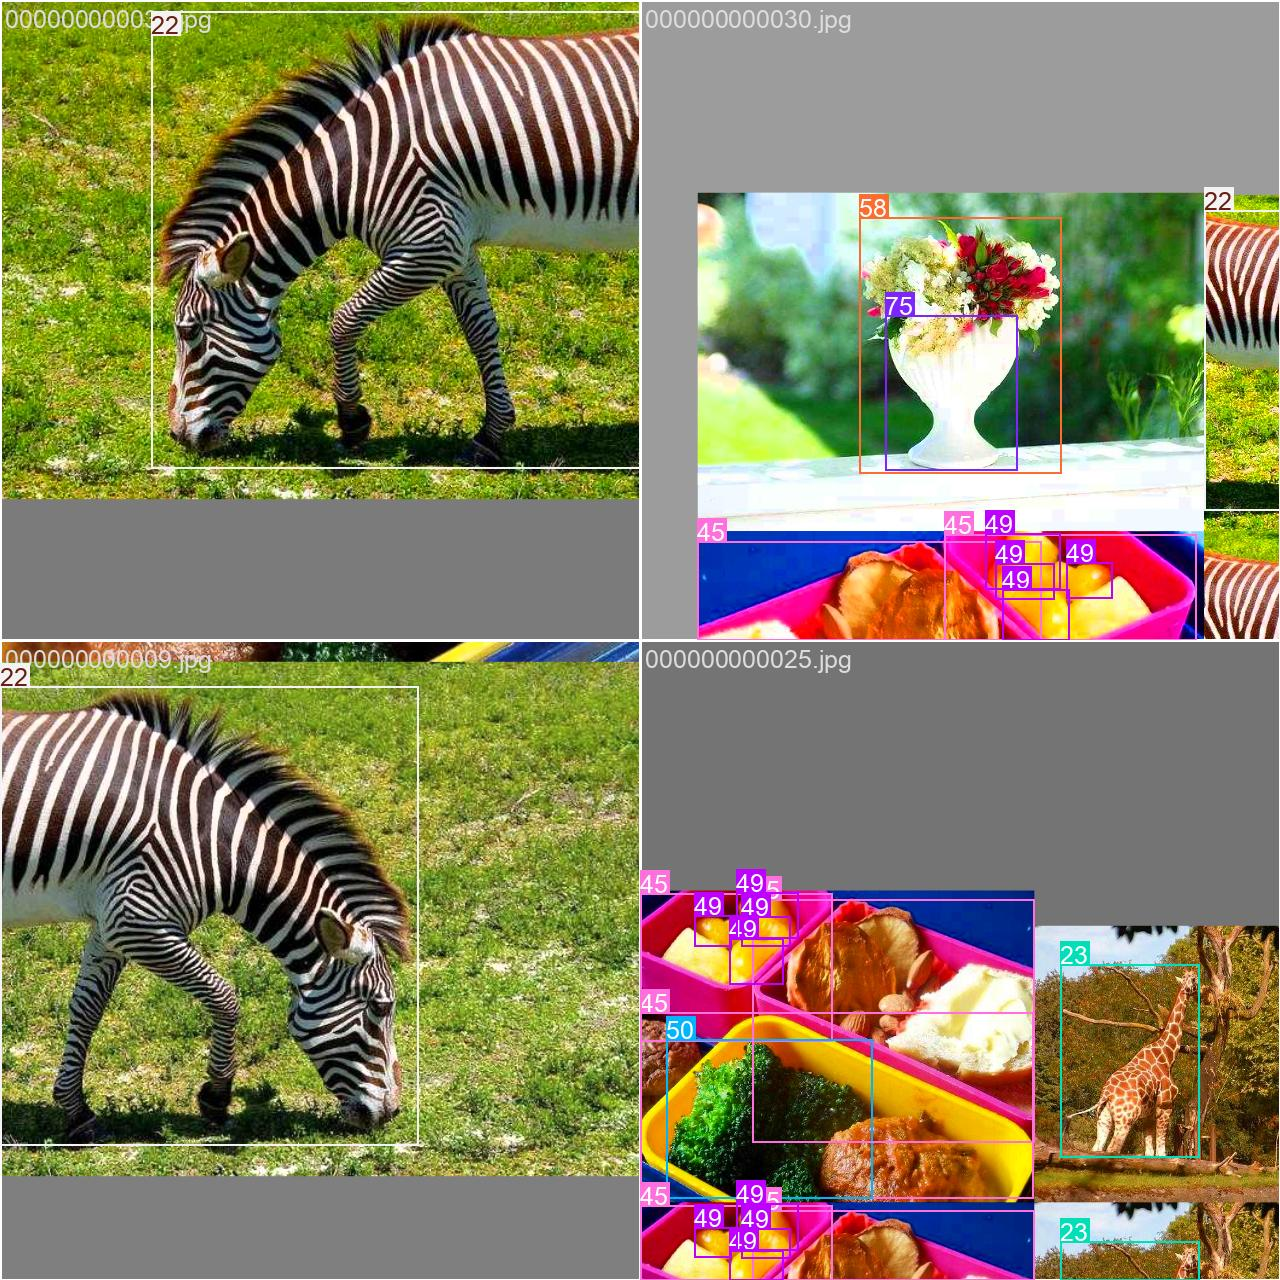


📊 val_batch0_pred.jpg


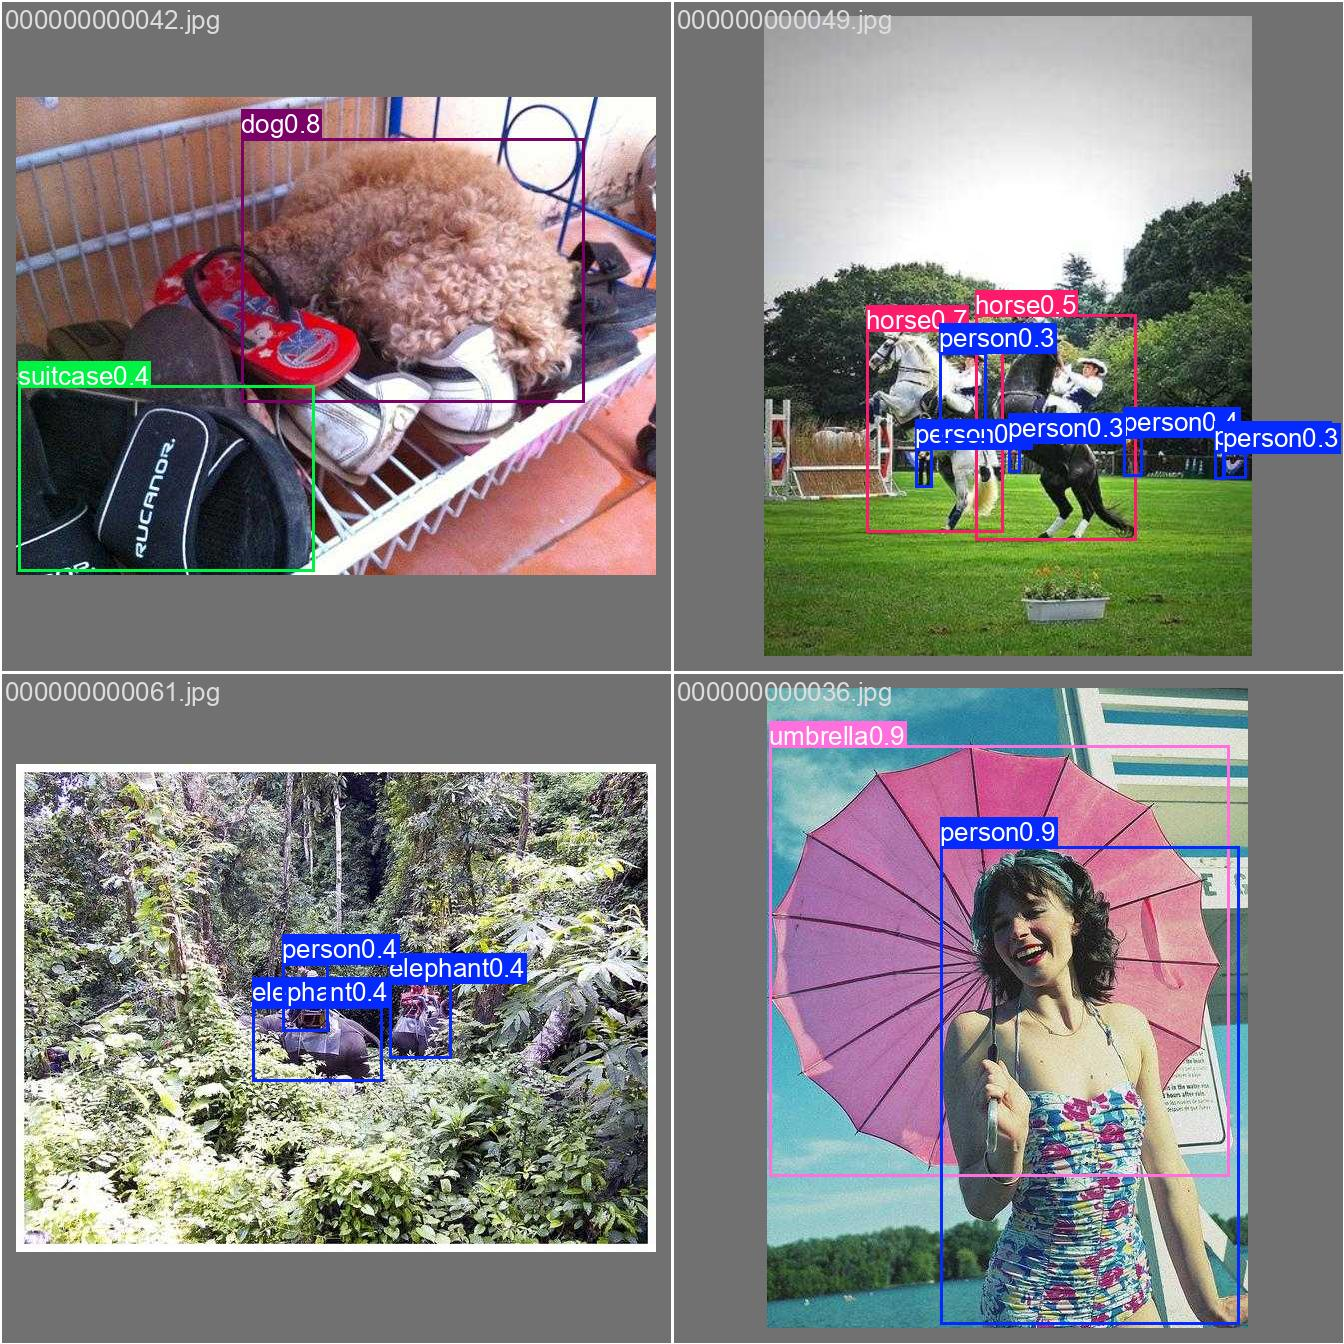

(tidak ada: PR_curve.png )
(tidak ada: F1_curve.png )


In [12]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

# @title 3.2 Tampilkan kurva training
from IPython.display import Image as IPyImage, display
import glob

if not SKIP_TRAINING:
    rd = WORKDIR / "runs" / "detect" / "train"
    for f in ["results.png", "confusion_matrix.png", "train_batch0.jpg",
              "val_batch0_pred.jpg", "PR_curve.png", "F1_curve.png"]:
        p = rd / f
        if p.exists():
            print("\n📊", f)
            display(IPyImage(filename=str(p), width=820))
        else:
            print("(tidak ada:", f, ")")

---
# 4) Evaluasi — IoU, Precision, Recall, AP, dan mAP

## 4.1 Definisi singkat

**Intersection over Union (IoU)** — seberapa tepat kotak prediksi menutupi
kotak ground truth:

$$\mathrm{IoU} = \frac{|B_{pred} \cap B_{gt}|}{|B_{pred} \cup B_{gt}|} \in [0,1]$$

IoU dipakai di dua tempat:
1. **NMS** — menghapus kotak ganda pada objek yang sama (threshold ≈ 0.45–0.60).
2. **Penentu benar/salah** — prediksi dihitung *True Positive* bila
   $\mathrm{IoU} \ge t$ dan kelasnya sama (COCO memakai $t = 0.50, 0.55, \dots, 0.95$).

**TP / FP / FN**
* TP = objek ada, terdeteksi, IoU ≥ t, kelas benar.
* FP = ditebak ada padahal tidak ada (alarm palsu) — atau IoU < t.
* FN = objek ada tetapi **tidak terdeteksi** (penyusup lolos).

$$\mathrm{Precision} = \frac{TP}{TP+FP} \qquad
  \mathrm{Recall} = \frac{TP}{TP+FN}$$

**Average Precision (AP)** = luas di bawah kurva Precision–Recall untuk satu
kelas. **mAP** = rata-rata AP seluruh kelas.
* **mAP@0.50** — satu ambang longgar: "apakah objeknya ketemu?"
* **mAP@0.50:0.95** — rata-rata 10 ambang IoU (metrik utama COCO): menuntut
  lokalisasi yang presisi.

In [13]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

# @title 4.1 Evaluasi dengan Ultralytics (`model.val()`)
_val_data = DATA_YAML or "coco8.yaml"
if DATA_YAML is None:
    print("📌 DATA_YAML belum diisi -> memakai coco8.yaml untuk validasi")
metrics = model.val(data=_val_data,
                    imgsz=IMG_SIZE, conf=0.001, iou=0.6,
                    device=DEVICE, split="val", plots=True, verbose=False)

print("=" * 66)
print("  HASIL VALIDASI ( Ultralytics )")
print("=" * 66)
print(f"Precision       : {metrics.results_dict.get('metrics/precision(B)', float('nan')):.4f}")
print(f"Recall          : {metrics.results_dict.get('metrics/recall(B)',    float('nan')):.4f}")
print(f"mAP@0.50        : {metrics.results_dict.get('metrics/mAP50(B)',     float('nan')):.4f}")
print(f"mAP@0.50:0.95   : {metrics.results_dict.get('metrics/mAP50-95(B)',  float('nan')):.4f}")
print("=" * 66)
if hasattr(metrics, "box") and hasattr(metrics.box, "ap_class_index"):
    print("\nPer kelas (AP@0.50 | AP@0.50:0.95):")
    for i, ci in enumerate(metrics.box.ap_class_index):
        nm = metrics.names[int(ci)]
        print(f"  {nm:<12} {metrics.box.ap50[i]:.4f} | {metrics.box.ap[i]:.4f}")

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1651.1±693.1 MB/s, size: 54.0 KB)
val: Scanning /content/datasets/coco8/labels/val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 10.0it/s 0.1s
                   all          4         17      0.608       0.85      0.861      0.637
Speed: 0.5ms preprocess, 11.7ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /content/drive/MyDrive/securevision/runs/detect/val
  HASIL VALIDASI ( Ultralytics )
Precision       : 0.6085
Recall          : 0.8500
mAP@0.50        : 0.8608
mAP@0.50:0.95   : 0.6366

Per kelas (AP@0.50 | AP@0.50:0.95):
  person       0.6480 | 0.2974
  dog          0.9950 | 0.7960
  horse        0.995

## 4.2 Implementasi IoU, Precision, Recall, AP, dan mAP **dari nol**

Sel di bawah **sengaja tidak memakai library metrik** — ditulis manual supaya
konsepnya benar-benar terlihat (dan bisa dipertanggungjawabkan saat presentasi).
Hasilnya lalu dibandingkan dengan angka Ultralytics di atas.

In [14]:
# @title 4.2 Implementasi manual metrik deteksi objek
import numpy as np

def iou(box_a, box_b):
    '''IoU = |A ∩ B| / |A ∪ B|  (Jaccard index), nilai 0..1'''
    ax1, ay1, ax2, ay2 = map(float, box_a)
    bx1, by1, bx2, by2 = map(float, box_b)
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

def iou_matrix(preds, gts):
    return np.array([[iou(p, g) for g in gts] for p in preds]) if preds and gts \
        else np.zeros((len(preds), len(gts)))

def match(pred_boxes, pred_scores, pred_classes, gt_boxes, gt_classes, t=0.5):
    '''
    Greedy matching per kelas, urut dari confidence tertinggi.
    Satu ground truth hanya boleh diklaim sekali (sisanya = FP).
    Return (pred_match, gt_match): -1 artinya tidak cocok.
    '''
    pred_match = [-1] * len(pred_boxes)
    gt_match   = [-1] * len(gt_boxes)
    for pi in np.argsort(-np.asarray(pred_scores, dtype=float)):
        best_iou, best_gi = t, -1
        for gi in range(len(gt_boxes)):
            if gt_match[gi] != -1:                       # sudah diklaim
                continue
            if pred_classes[pi] != gt_classes[gi]:       # kelas harus sama
                continue
            v = iou(pred_boxes[pi], gt_boxes[gi])
            if v > best_iou:
                best_iou, best_gi = v, gi
        if best_gi >= 0:
            pred_match[pi], gt_match[best_gi] = best_gi, pi
    return pred_match, gt_match

def precision_recall(tp, fp, fn):
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    return p, r

def f_beta(p, r, beta=1.0):
    '''beta=2 -> F2, memberi bobot 4x pada recall (cocok untuk keamanan)'''
    if p + r == 0: return 0.0
    b2 = beta ** 2
    return (1 + b2) * p * r / (b2 * p + r)

def pr_curve(pred_boxes, pred_scores, pred_classes, gt_boxes, gt_classes,
             t=0.5, class_id=None):
    if class_id is not None:
        pred_boxes   = [b for b, c in zip(pred_boxes,   pred_classes) if c == class_id]
        pred_scores  = [s for s, c in zip(pred_scores,  pred_classes) if c == class_id]
        pred_classes = [c for c in pred_classes if c == class_id]
        gt_boxes     = [b for b, c in zip(gt_boxes, gt_classes) if c == class_id]
        gt_classes   = [c for c in gt_classes if c == class_id]
    n_gt = len(gt_boxes)
    if n_gt == 0 or not pred_boxes:
        return np.array([0.0, 1.0]), np.array([0.0, 0.0])
    order = np.argsort(-np.asarray(pred_scores, dtype=float))
    tp = np.zeros(len(order)); fp = np.zeros(len(order)); used = set()
    for rank, pi in enumerate(order):
        best_iou, best_gi = t, -1
        for gi in range(n_gt):
            if gi in used or pred_classes[pi] != gt_classes[gi]:
                continue
            v = iou(pred_boxes[pi], gt_boxes[gi])
            if v > best_iou: best_iou, best_gi = v, gi
        if best_gi >= 0: tp[rank] = 1; used.add(best_gi)
        else:            fp[rank] = 1
    rec  = np.cumsum(tp) / n_gt
    prec = np.cumsum(tp) / np.maximum(np.cumsum(tp) + np.cumsum(fp), 1e-12)
    prec = np.maximum.accumulate(prec[::-1])[::-1]        # monoton turun (VOC)
    return np.concatenate(([0.0], rec, [1.0])), np.concatenate(([1.0], prec, [0.0]))

def average_precision(pb, ps, pc, gb, gc, t=0.5, class_id=None, method="all"):
    '''AP = luas di bawah kurva PR (all-point interpolation, standar COCO)'''
    rec, prec = pr_curve(pb, ps, pc, gb, gc, t, class_id)
    if method == "11point":                                # gaya VOC 2007
        return float(np.mean([prec[rec >= x].max() if np.any(rec >= x) else 0.0
                              for x in np.linspace(0, 1, 11)]))
    o = np.argsort(rec); r, p = rec[o], prec[o]
    return float(np.sum(np.diff(r) * p[1:]))

def mean_average_precision(pb, ps, pc, gb, gc, iou_thrs=(0.5,), class_ids=None):
    '''mAP = rata-rata AP terhadap kelas (dan terhadap ambang IoU)'''
    cls = sorted(set(list(gc) + list(pc))) if class_ids is None else list(class_ids)
    per = {}
    for t in iou_thrs:
        aps = [average_precision(pb, ps, pc, gb, gc, t, c) for c in cls]
        per[t] = float(np.mean(aps)) if aps else 0.0
    return {"per_threshold": per, "mAP": float(np.mean(list(per.values())))}

COCO_THRS = tuple(np.arange(0.50, 1.00, 0.05))            # 0.50 ... 0.95
print("✅ Fungsi metrik siap: iou, match, precision_recall, f_beta,")
print("   pr_curve, average_precision, mean_average_precision")

✅ Fungsi metrik siap: iou, match, precision_recall, f_beta,
   pr_curve, average_precision, mean_average_precision


IoU [0,0,10,10] vs [0,0,10,10]       = 1.000  -> TP jika threshold <= nilai ini
IoU [0,0,10,10] vs [5,0,15,10]       = 0.333  -> TP jika threshold <= nilai ini
IoU [0,0,10,10] vs [8,0,18,10]       = 0.111  -> TP jika threshold <= nilai ini
IoU [0,0,10,10] vs [50,50,60,60]     = 0.000  -> TP jika threshold <= nilai ini


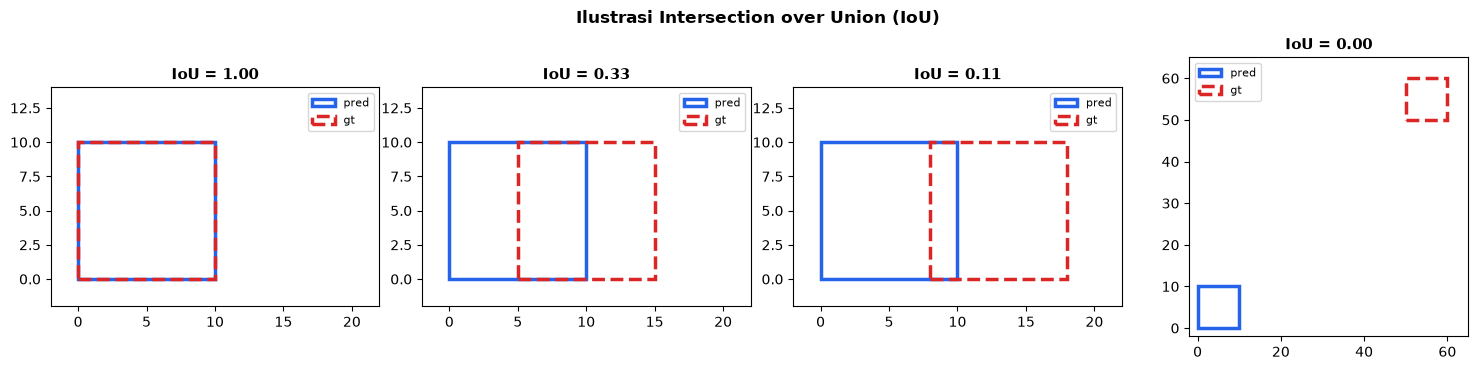


TP=2  FP=1  FN=1
Precision = 2/3 = 0.667
Recall    = 2/3 = 0.667
F1 = 0.667   F2 (recall-weighted) = 0.667
AP@0.50   = 0.667
mAP@.50:.95 = 0.400


In [15]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

import numpy as np

def iou(box_a, box_b):
    '''IoU = |A ∩ B| / |A ∪ B|  (Jaccard index), nilai 0..1'''
    ax1, ay1, ax2, ay2 = map(float, box_a)
    bx1, by1, bx2, by2 = map(float, box_b)
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

def iou_matrix(preds, gts):
    return np.array([[iou(p, g) for g in gts] for p in preds]) if preds and gts \
        else np.zeros((len(preds), len(gts)))

def match(pred_boxes, pred_scores, pred_classes, gt_boxes, gt_classes, t=0.5):
    '''
    Greedy matching per kelas, urut dari confidence tertinggi.
    Satu ground truth hanya boleh diklaim sekali (sisanya = FP).
    Return (pred_match, gt_match): -1 artinya tidak cocok.
    '''
    pred_match = [-1] * len(pred_boxes)
    gt_match   = [-1] * len(gt_boxes)
    for pi in np.argsort(-np.asarray(pred_scores, dtype=float)):
        best_iou, best_gi = t, -1
        for gi in range(len(gt_boxes)):
            if gt_match[gi] != -1:                       # sudah diklaim
                continue
            if pred_classes[pi] != gt_classes[gi]:       # kelas harus sama
                continue
            v = iou(pred_boxes[pi], gt_boxes[gi])
            if v > best_iou:
                best_iou, best_gi = v, gi
        if best_gi >= 0:
            pred_match[pi], gt_match[best_gi] = best_gi, pi
    return pred_match, gt_match

def precision_recall(tp, fp, fn):
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    return p, r

def f_beta(p, r, beta=1.0):
    '''beta=2 -> F2, memberi bobot 4x pada recall (cocok untuk keamanan)'''
    if p + r == 0: return 0.0
    b2 = beta ** 2
    return (1 + b2) * p * r / (b2 * p + r)

def pr_curve(pred_boxes, pred_scores, pred_classes, gt_boxes, gt_classes,
             t=0.5, class_id=None):
    if class_id is not None:
        pred_boxes   = [b for b, c in zip(pred_boxes,   pred_classes) if c == class_id]
        pred_scores  = [s for s, c in zip(pred_scores,  pred_classes) if c == class_id]
        pred_classes = [c for c in pred_classes if c == class_id]
        gt_boxes     = [b for b, c in zip(gt_boxes, gt_classes) if c == class_id]
        gt_classes   = [c for c in gt_classes if c == class_id]
    n_gt = len(gt_boxes)
    if n_gt == 0 or not pred_boxes:
        return np.array([0.0, 1.0]), np.array([0.0, 0.0])
    order = np.argsort(-np.asarray(pred_scores, dtype=float))
    tp = np.zeros(len(order)); fp = np.zeros(len(order)); used = set()
    for rank, pi in enumerate(order):
        best_iou, best_gi = t, -1
        for gi in range(n_gt):
            if gi in used or pred_classes[pi] != gt_classes[gi]:
                continue
            v = iou(pred_boxes[pi], gt_boxes[gi])
            if v > best_iou: best_iou, best_gi = v, gi
        if best_gi >= 0: tp[rank] = 1; used.add(best_gi)
        else:            fp[rank] = 1
    rec  = np.cumsum(tp) / n_gt
    prec = np.cumsum(tp) / np.maximum(np.cumsum(tp) + np.cumsum(fp), 1e-12)
    prec = np.maximum.accumulate(prec[::-1])[::-1]        # monoton turun (VOC)
    return np.concatenate(([0.0], rec, [1.0])), np.concatenate(([1.0], prec, [0.0]))

def average_precision(pb, ps, pc, gb, gc, t=0.5, class_id=None, method="all"):
    '''AP = luas di bawah kurva PR (all-point interpolation, standar COCO)'''
    rec, prec = pr_curve(pb, ps, pc, gb, gc, t, class_id)
    if method == "11point":                                # gaya VOC 2007
        return float(np.mean([prec[rec >= x].max() if np.any(rec >= x) else 0.0
                              for x in np.linspace(0, 1, 11)]))
    o = np.argsort(rec); r, p = rec[o], prec[o]
    return float(np.sum(np.diff(r) * p[1:]))

def mean_average_precision(pb, ps, pc, gb, gc, iou_thrs=(0.5,), class_ids=None):
    '''mAP = rata-rata AP terhadap kelas (dan terhadap ambang IoU)'''
    cls = sorted(set(list(gc) + list(pc))) if class_ids is None else list(class_ids)
    per = {}
    for t in iou_thrs:
        aps = [average_precision(pb, ps, pc, gb, gc, t, c) for c in cls]
        per[t] = float(np.mean(aps)) if aps else 0.0
    return {"per_threshold": per, "mAP": float(np.mean(list(per.values())))}

COCO_THRS = tuple(np.arange(0.50, 1.00, 0.05))            # 0.50 ... 0.95

# @title 4.3 Uji pemahaman metrik pada kasus MAINAN (bisa dijelaskan ke dosen)
import matplotlib.pyplot as plt

# dua box identik, dua box bergeser, satu box meleset jauh
demo = [("[0,0,10,10] vs [0,0,10,10]", [0,0,10,10],   [0,0,10,10]),
        ("[0,0,10,10] vs [5,0,15,10]", [0,0,10,10],   [5,0,15,10]),
        ("[0,0,10,10] vs [8,0,18,10]", [0,0,10,10],   [8,0,18,10]),
        ("[0,0,10,10] vs [50,50,60,60]", [0,0,10,10], [50,50,60,60])]
for label, a, b in demo:
    print(f"IoU {label:<32} = {iou(a,b):.3f}  -> TP jika threshold <= nilai ini")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for k, (label, a, b) in enumerate(demo):
    ax[k].add_patch(plt.Rectangle((a[0], a[1]), a[2]-a[0], a[3]-a[1],
                                  fill=False, ec="#2563EB", lw=2.5, label="pred"))
    ax[k].add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1],
                                  fill=False, ec="#DC2626", lw=2.5, ls="--", label="gt"))
    ax[k].set_title(f"IoU = {iou(a,b):.2f}", fontsize=11, fontweight="bold")
    ax[k].set_xlim(-2, 22 if k < 3 else 65); ax[k].set_ylim(-2, 14 if k < 3 else 65)
    ax[k].set_aspect("equal"); ax[k].legend(fontsize=8)
plt.suptitle("Ilustrasi Intersection over Union (IoU)", fontweight="bold")
plt.tight_layout(); plt.show()

# --- contoh perhitungan TP/FP/FN, Precision, Recall ---
gt_boxes   = [[10,10,60,60], [100,100,160,160], [200,200,250,250]]   # 3 objek asli
gt_classes = [0, 0, 0]
pb = [[12,12,58,58], [300,300,340,340], [205,205,248,248]]           # 3 prediksi
ps = [0.95, 0.40, 0.70]
pc = [0, 0, 0]
pm, gm = match(pb, ps, pc, gt_boxes, gt_classes, t=0.5)
tp = sum(1 for m in pm if m >= 0); fp = sum(1 for m in pm if m < 0)
fn = sum(1 for m in gm if m < 0)
P, R = precision_recall(tp, fp, fn)
print(f"\nTP={tp}  FP={fp}  FN={fn}")
print(f"Precision = {tp}/{tp+fp} = {P:.3f}")
print(f"Recall    = {tp}/{tp+fn} = {R:.3f}")
print(f"F1 = {f_beta(P,R,1):.3f}   F2 (recall-weighted) = {f_beta(P,R,2):.3f}")
print(f"AP@0.50   = {average_precision(pb,ps,pc,gt_boxes,gt_classes,0.5):.3f}")
print(f"mAP@.50:.95 = {mean_average_precision(pb,ps,pc,gt_boxes,gt_classes,COCO_THRS)['mAP']:.3f}")

## 4.3 — lanjutan: hitung mAP **manual** di dataset validasi sungguhan

Sel ini menjalankan model pada folder `valid/images`, membaca ground truth
`valid/labels/*.txt` (format YOLO `cls cx cy w h` ternormalisasi), lalu
menghitung mAP dengan fungsi buatan sendiri. Bandingkan dengan angka
Ultralytics di sel 4.1 — nilainya harus **berdekatan** (beda kecil wajar
karena detail implementasi NMS/interpolasi).

In [16]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------


# --- helper data validasi (aman bila sel 4.4 belum dijalankan) ---------------
try:
    from ultralytics.utils.checks import check_file as _check_file
except Exception:
    def _check_file(p, *a, **k):
        return p

def _resolve_yaml(p):
    # temukan berkas .yaml (mendukung nama bawaan seperti 'coco8.yaml')
    try:
        return Path(str(_check_file(str(p))))
    except Exception:
        return Path(str(p))

def yolo_to_xyxy(line, w, h):
    c, cx, cy, bw, bh = line.split()[:5]
    cx, cy, bw, bh = float(cx) * w, float(cy) * h, float(bw) * w, float(bh) * h
    return [cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2]

def load_split(root, split="valid"):
    root = Path(root)
    img_dir = next((p for p in [root / split / "images",
                                root / "images" / split] if p.is_dir()), None)
    lbl_dir = next((p for p in [root / split / "labels",
                                root / "labels" / split] if p.is_dir()), None)
    if img_dir is None or lbl_dir is None:
        return []
    items = []
    for ip in sorted(img_dir.glob("*")):
        if ip.suffix.lower() not in (".jpg", ".jpeg", ".png", ".bmp"):
            continue
        lp = lbl_dir / (ip.stem + ".txt")
        items.append((str(ip), str(lp) if lp.exists() else None))
    return items
# --- akhir helper data -------------------------------------------------------

# @title 4.4 mAP manual pada data validasi
from pathlib import Path

def yolo_to_xyxy(line, w, h):
    c, cx, cy, bw, bh = line.split()[:5]
    cx, cy, bw, bh = float(cx)*w, float(cy)*h, float(bw)*w, float(bh)*h
    return [cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2]

def load_split(root: Path, split="valid"):
    root = Path(root)
    img_dir = next((p for p in [root/split/"images", root/"images"/split] if p.is_dir()), None)
    lbl_dir = next((p for p in [root/split/"labels", root/"labels"/split] if p.is_dir()), None)
    if img_dir is None or lbl_dir is None:
        return []
    items = []
    for ip in sorted(img_dir.glob("*")):
        if ip.suffix.lower() not in (".jpg", ".jpeg", ".png", ".bmp"):
            continue
        lp = lbl_dir / (ip.stem + ".txt")
        items.append((str(ip), str(lp) if lp.exists() else None))
    return items

def compute_map_manual(model, data_yaml, split="valid", conf=0.001, iou_nms=0.6,
                       class_ids=(0,1,2,3), max_images=None):
    import cv2, yaml
    cfg = yaml.safe_load(_resolve_yaml(data_yaml).read_text())
    root = Path(cfg["path"])
    items = load_split(root, split)
    if not items:
        print(f"Split '{split}' tidak ditemukan pada {root}.")
        print("-> Untuk coco8, jalankan sel 4.1 (model.val) sekali agar dataset terunduh.")
        return None
    if max_images: items = items[:max_images]

    GT_B, GT_C, PB, PS, PC = [], [], [], [], []
    for ip, lp in tqdm(items, desc=f"infer {split}", leave=False):
        img = cv2.imread(ip); h, w = img.shape[:2]
        g_b, g_c = [], []
        if lp and Path(lp).exists():
            for line in Path(lp).read_text().splitlines():
                if not line.strip(): continue
                cid = int(line.split()[0])
                if cid not in class_ids: continue
                g_b.append(yolo_to_xyxy(line, w, h)); g_c.append(cid)
        r = model.predict(img, imgsz=IMG_SIZE, conf=conf, iou=iou_nms,
                          device=DEVICE, verbose=False)[0]
        p_b = [list(map(float, b.xyxy[0])) for b in r.boxes]
        p_s = [float(b.conf) for b in r.boxes]
        p_c = [int(b.cls)   for b in r.boxes]
        GT_B.append(g_b); GT_C.append(g_c)
        PB.append(p_b);   PS.append(p_s); PC.append(p_c)

    # gabungkan (cara micro-average; cukup untuk verifikasi konsep)
    FB  = [b for s in PB for b in s]
    FS  = [s for s in PS]
    FC  = [c for c in PC]
    GB  = [b for s in GT_B for b in s]
    GC  = [c for s in GT_C for c in s]

    res = {"mAP@0.50": average_precision(FB, FS, FC, GB, GC, 0.5),
           "mAP@0.75": average_precision(FB, FS, FC, GB, GC, 0.75),
           "mAP@0.50:0.95": mean_average_precision(FB, FS, FC, GB, GC, COCO_THRS)["mAP"]}
    pm, gm = match(FB, FS, FC, GB, GC, 0.5)
    tp = sum(1 for m in pm if m >= 0); fp = sum(1 for m in pm if m < 0)
    fn = sum(1 for m in gm if m < 0)
    P, R = precision_recall(tp, fp, fn)
    res.update({"TP": tp, "FP": fp, "FN": fn, "Precision": P, "Recall": R,
                "F1": f_beta(P, R, 1), "F2": f_beta(P, R, 2),
                "n_gt": len(GB), "n_pred": len(FB), "n_images": len(items)})
    return res

_yaml = DATA_YAML or "coco8.yaml"
if DATA_YAML is None:
    print("📌 DATA_YAML belum diisi -> memakai coco8.yaml (jalankan sel 2.3 untuk datasetmu)")
manual = compute_map_manual(model, _yaml, split="valid", max_images=None)
if manual:
    print("\n" + "=" * 58)
    print("   mAP DIHITUNG MANUAL (implementasi sendiri)")
    print("=" * 58)
    for k, v in manual.items():
        print(f"  {k:<15}: {v:.4f}" if isinstance(v, float) else f"  {k:<15}: {v}")
    print("=" * 58)
else:
    print("⏭️  Tidak ada data validasi yang bisa dievaluasi.")

Split 'valid' tidak ditemukan pada coco8.
-> Untuk coco8, jalankan sel 4.1 (model.val) sekali agar dataset terunduh.
⏭️  Tidak ada data validasi yang bisa dievaluasi.


## 4.4 Metrik mana yang PALING KRUSIAL untuk kamera keamanan?

> **Jawaban: RECALL** — dengan catatan recall diukur pada ambang IoU yang
> longgar (mis. IoU ≥ 0.50) dan *operating point* (confidence threshold) yang
> dipilih memang untuk *deployment*, bukan nilai default.

**Alasannya.** Biaya kesalahan pada sistem keamanan sangat tidak simetris:

| Kondisi | Nama metrik | Akibat | Biaya |
|---|---|---|---|
| Penyusup **tidak** terdeteksi | **False Negative → Recall turun** | Maling lolos, barang hilang, rekaman tak ada | 🔴 **Sangat mahal & tidak bisa diulang** |
| Alarm berbunyi padahal kucing lewat | False Positive → Precision turun | Petugas mengecek CCTV | 🟡 Murah, hanya mengganggu |

Secara matematis: **Recall = TP / (TP + FN)**. FN adalah kegagalan yang ingin
dihindari, jadi recall adalah metrik yang **berbanding terbalik langsung**
dengan jumlah penyusup yang lolos.

**mAP bukan jawabannya**, karena mAP adalah *rata-rata atas seluruh operating
point* (seluruh nilai confidence) dan seluruh ambang IoU 0.50–0.95. Sistem
nyata hanya berjalan pada **satu** nilai confidence. mAP bagus (mis. 0.85)
bisa saja menyembunyikan recall 0.55 pada threshold yang dipakai.
mAP tetap dipakai, tetapi untuk **memilih/memilih-membandingkan model**, bukan
untuk memastikan tidak ada penyusup lolos.

**Precision** juga penting, tapi urutan keduanya: precision rendah hanya
membuat petugas lelah (*alarm fatigue*) — dampaknya lambat, bukan fatal.

### Strategi optimasinya (konkret)
1. **Turunkan confidence threshold** untuk kelas kritis → recall naik.
2. **Pakai threshold per-kelas**: `person` paling rendah (0.25–0.30),
   `car/truck/motorbike` lebih tinggi (0.40).
3. **Longgarkan IoU NMS** sedikit (0.45 → 0.60) agar objek yang berhimpitan
   (kerumunan) tidak terhapus.
4. **Optimalkan F2-score, bukan F1** — F2 memberi bobot recall 4× lipat:
   $$F_\beta = \frac{(1+\beta^2)PR}{\beta^2 P + R},\quad \beta = 2$$
5. **Tetapkan target berdasar recall**, contoh: *"Recall(person) ≥ 0.95 pada
   IoU ≥ 0.50 dengan Precision ≥ 0.70"*. Lalu cari threshold yang memenuhi
   keduanya (lihat sel 4.5: *threshold sweep*).
6. **Tambah data *hard negative* & kondisi malam** ke dataset, lalu fine-tune
   ulang — ini menaikkan recall tanpa mengorbankan precision.

In [17]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

import numpy as np

def iou(box_a, box_b):
    '''IoU = |A ∩ B| / |A ∪ B|  (Jaccard index), nilai 0..1'''
    ax1, ay1, ax2, ay2 = map(float, box_a)
    bx1, by1, bx2, by2 = map(float, box_b)
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

def iou_matrix(preds, gts):
    return np.array([[iou(p, g) for g in gts] for p in preds]) if preds and gts \
        else np.zeros((len(preds), len(gts)))

def match(pred_boxes, pred_scores, pred_classes, gt_boxes, gt_classes, t=0.5):
    '''
    Greedy matching per kelas, urut dari confidence tertinggi.
    Satu ground truth hanya boleh diklaim sekali (sisanya = FP).
    Return (pred_match, gt_match): -1 artinya tidak cocok.
    '''
    pred_match = [-1] * len(pred_boxes)
    gt_match   = [-1] * len(gt_boxes)
    for pi in np.argsort(-np.asarray(pred_scores, dtype=float)):
        best_iou, best_gi = t, -1
        for gi in range(len(gt_boxes)):
            if gt_match[gi] != -1:                       # sudah diklaim
                continue
            if pred_classes[pi] != gt_classes[gi]:       # kelas harus sama
                continue
            v = iou(pred_boxes[pi], gt_boxes[gi])
            if v > best_iou:
                best_iou, best_gi = v, gi
        if best_gi >= 0:
            pred_match[pi], gt_match[best_gi] = best_gi, pi
    return pred_match, gt_match

def precision_recall(tp, fp, fn):
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    return p, r

def f_beta(p, r, beta=1.0):
    '''beta=2 -> F2, memberi bobot 4x pada recall (cocok untuk keamanan)'''
    if p + r == 0: return 0.0
    b2 = beta ** 2
    return (1 + b2) * p * r / (b2 * p + r)

def pr_curve(pred_boxes, pred_scores, pred_classes, gt_boxes, gt_classes,
             t=0.5, class_id=None):
    if class_id is not None:
        pred_boxes   = [b for b, c in zip(pred_boxes,   pred_classes) if c == class_id]
        pred_scores  = [s for s, c in zip(pred_scores,  pred_classes) if c == class_id]
        pred_classes = [c for c in pred_classes if c == class_id]
        gt_boxes     = [b for b, c in zip(gt_boxes, gt_classes) if c == class_id]
        gt_classes   = [c for c in gt_classes if c == class_id]
    n_gt = len(gt_boxes)
    if n_gt == 0 or not pred_boxes:
        return np.array([0.0, 1.0]), np.array([0.0, 0.0])
    order = np.argsort(-np.asarray(pred_scores, dtype=float))
    tp = np.zeros(len(order)); fp = np.zeros(len(order)); used = set()
    for rank, pi in enumerate(order):
        best_iou, best_gi = t, -1
        for gi in range(n_gt):
            if gi in used or pred_classes[pi] != gt_classes[gi]:
                continue
            v = iou(pred_boxes[pi], gt_boxes[gi])
            if v > best_iou: best_iou, best_gi = v, gi
        if best_gi >= 0: tp[rank] = 1; used.add(best_gi)
        else:            fp[rank] = 1
    rec  = np.cumsum(tp) / n_gt
    prec = np.cumsum(tp) / np.maximum(np.cumsum(tp) + np.cumsum(fp), 1e-12)
    prec = np.maximum.accumulate(prec[::-1])[::-1]        # monoton turun (VOC)
    return np.concatenate(([0.0], rec, [1.0])), np.concatenate(([1.0], prec, [0.0]))

def average_precision(pb, ps, pc, gb, gc, t=0.5, class_id=None, method="all"):
    '''AP = luas di bawah kurva PR (all-point interpolation, standar COCO)'''
    rec, prec = pr_curve(pb, ps, pc, gb, gc, t, class_id)
    if method == "11point":                                # gaya VOC 2007
        return float(np.mean([prec[rec >= x].max() if np.any(rec >= x) else 0.0
                              for x in np.linspace(0, 1, 11)]))
    o = np.argsort(rec); r, p = rec[o], prec[o]
    return float(np.sum(np.diff(r) * p[1:]))

def mean_average_precision(pb, ps, pc, gb, gc, iou_thrs=(0.5,), class_ids=None):
    '''mAP = rata-rata AP terhadap kelas (dan terhadap ambang IoU)'''
    cls = sorted(set(list(gc) + list(pc))) if class_ids is None else list(class_ids)
    per = {}
    for t in iou_thrs:
        aps = [average_precision(pb, ps, pc, gb, gc, t, c) for c in cls]
        per[t] = float(np.mean(aps)) if aps else 0.0
    return {"per_threshold": per, "mAP": float(np.mean(list(per.values())))}

COCO_THRS = tuple(np.arange(0.50, 1.00, 0.05))            # 0.50 ... 0.95


# --- helper data validasi (aman bila sel 4.4 belum dijalankan) ---------------
try:
    from ultralytics.utils.checks import check_file as _check_file
except Exception:
    def _check_file(p, *a, **k):
        return p

def _resolve_yaml(p):
    # temukan berkas .yaml (mendukung nama bawaan seperti 'coco8.yaml')
    try:
        return Path(str(_check_file(str(p))))
    except Exception:
        return Path(str(p))

def yolo_to_xyxy(line, w, h):
    c, cx, cy, bw, bh = line.split()[:5]
    cx, cy, bw, bh = float(cx) * w, float(cy) * h, float(bw) * w, float(bh) * h
    return [cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2]

def load_split(root, split="valid"):
    root = Path(root)
    img_dir = next((p for p in [root / split / "images",
                                root / "images" / split] if p.is_dir()), None)
    lbl_dir = next((p for p in [root / split / "labels",
                                root / "labels" / split] if p.is_dir()), None)
    if img_dir is None or lbl_dir is None:
        return []
    items = []
    for ip in sorted(img_dir.glob("*")):
        if ip.suffix.lower() not in (".jpg", ".jpeg", ".png", ".bmp"):
            continue
        lp = lbl_dir / (ip.stem + ".txt")
        items.append((str(ip), str(lp) if lp.exists() else None))
    return items
# --- akhir helper data -------------------------------------------------------

# @title 4.5 Threshold sweep — memilih confidence threshold terbaik (maksimalkan F2)
import matplotlib.pyplot as plt

def sweep(model, data_yaml, split="valid", class_ids=(0,1,2,3), max_images=60):
    import cv2, yaml
    cfg = yaml.safe_load(_resolve_yaml(data_yaml).read_text())
    items = load_split(Path(cfg["path"]), split)[:max_images]
    if not items:
        print("Split validasi kosong."); return None, None
    # kumpulkan prediksi sekali pada conf sangat rendah, lalu sweep secara analitik
    FB, FS, FC, GB, GC = [], [], [], [], []
    for ip, lp in tqdm(items, desc="kumpulkan prediksi", leave=False):
        img = cv2.imread(ip); h, w = img.shape[:2]
        g_b, g_c = [], []
        if lp and Path(lp).exists():
            for line in Path(lp).read_text().splitlines():
                if not line.strip(): continue
                cid = int(line.split()[0])
                if cid not in class_ids: continue
                g_b.append(yolo_to_xyxy(line, w, h)); g_c.append(cid)
        r = model.predict(img, imgsz=IMG_SIZE, conf=0.001, iou=IOU_NMS,
                          device=DEVICE, verbose=False)[0]
        FB += [list(map(float, b.xyxy[0])) for b in r.boxes]
        FS += [float(b.conf) for b in r.boxes]
        FC += [int(b.cls) for b in r.boxes]
        GB += g_b; GC += g_c
    rows = []
    for thr in np.round(np.arange(0.05, 0.95, 0.05), 2):
        keep = [i for i, s in enumerate(FS) if s >= thr]
        pb = [FB[i] for i in keep]; ps = [FS[i] for i in keep]; pc = [FC[i] for i in keep]
        pm, gm = match(pb, ps, pc, GB, GC, 0.5)
        tp = sum(1 for m in pm if m >= 0); fp = sum(1 for m in pm if m < 0)
        fn = sum(1 for m in gm if m < 0)
        P, R = precision_recall(tp, fp, fn)
        rows.append({"conf": float(thr), "precision": P, "recall": R,
                     "f1": f_beta(P, R, 1), "f2": f_beta(P, R, 2),
                     "fp": fp, "fn": fn})
    return rows, (GB, GC, FB, FS, FC)

_yaml = DATA_YAML or "coco8.yaml"
if DATA_YAML is None:
    print("📌 DATA_YAML belum diisi -> memakai coco8.yaml (jalankan sel 2.3 untuk datasetmu)")
rows, bundle = sweep(model, _yaml)
if not rows:
    print("⏭️  Tidak ada data validasi untuk sweep.")
else:
    df = pd.DataFrame(rows)
    best_f2 = df.loc[df.f2.idxmax()]
    best_f1 = df.loc[df.f1.idxmax()]
    # threshold terendah yang masih menjaga recall >= 0.95
    cand = df[df.recall >= 0.95]
    safe = cand.iloc[0] if len(cand) else df.iloc[0]

    print("\n" + "=" * 74)
    print("  SWEEP CONFIDENCE THRESHOLD")
    print("=" * 74)
    print(df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    print("-" * 74)
    print(f"Threshold terbaik utk F1 : conf={best_f1.conf:.2f} "
          f"(P={best_f1.precision:.3f}, R={best_f1.recall:.3f}, F1={best_f1.f1:.3f})")
    print(f"Threshold terbaik utk F2 : conf={best_f2.conf:.2f} "
          f"(P={best_f2.precision:.3f}, R={best_f2.recall:.3f}, F2={best_f2.f2:.3f})")
    print(f"Paling AMAN (R>=0.95)    : conf={safe.conf:.2f} "
          f"(P={safe.precision:.3f}, R={safe.recall:.3f}, FN={int(safe.fn)})")
    print("=" * 74)
    print(">>> Untuk kamera keamanan, pakai nilai 'Paling AMAN' (recall maksimal).")

    fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
    ax[0].plot(df["conf"], df["precision"], "o-", label="Precision", color="#2563EB")
    ax[0].plot(df["conf"], df["recall"],    "s-", label="Recall",    color="#16A34A")
    ax[0].plot(df["conf"], df["f1"],        "^--", label="F1",       color="#D97706")
    ax[0].plot(df["conf"], df["f2"],        "d--", label="F2 (recall-weighted)", color="#DC2626")
    ax[0].axvline(safe.conf, color="#DC2626", ls=":", lw=2)
    ax[0].text(safe.conf + 0.01, 0.05, f"pilih aman\nconf={safe.conf:.2f}",
               color="#DC2626", fontsize=9)
    ax[0].set_xlabel("Confidence threshold"); ax[0].set_ylabel("Nilai")
    ax[0].set_title("Precision / Recall vs Threshold", fontweight="bold")
    ax[0].legend(); ax[0].grid(alpha=.3)

    rec, prec = pr_curve(*bundle[2], *bundle[3], *bundle[4], bundle[0], bundle[1], 0.5)
    ap = average_precision(*bundle[2], *bundle[3], *bundle[4], bundle[0], bundle[1], 0.5)
    ax[1].plot(rec, prec, color="#2563EB", lw=2.5)
    ax[1].fill_between(rec, prec, alpha=.15, color="#2563EB")
    ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
    ax[1].set_title(f"Kurva Precision-Recall  (AP@0.50 = {ap:.3f})", fontweight="bold")
    ax[1].set_xlim(0, 1); ax[1].set_ylim(0, 1.05); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

Split validasi kosong.
⏭️  Tidak ada data validasi untuk sweep.


---
# 5) Demo Webcam Live (langsung di Colab)

Sel di bawah memakai JavaScript `getUserMedia` supaya kamera laptop/HP-mu
bisa dipakai **langsung dari browser Colab** — hasilnya sama persis dengan
logika yang dipakai aplikasi desktop (ambil frame → inferensi → filter 4 kelas
→ gambar kotak).

**Catatan:** browser akan meminta izin kamera. Kalau tombol *Capture* tidak
muncul, ulangi: `Runtime → Restart runtime`, lalu jalankan ulang sel ini.

In [18]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

# @title 5.1 Webcam live detection di browser
from IPython.display import display, Javascript, Image as IPyImage
from google.colab.output import eval_js
from base64 import b64decode
import numpy as np, cv2

def js_to_image(js_reply):
    '''ubah balasan JS (base64) -> frame BGR OpenCV'''
    image_bytes = b64decode(js_reply.split(",")[1])
    nparr = np.frombuffer(image_bytes, np.uint8)
    return cv2.imdecode(nparr, cv2.IMREAD_COLOR)

def bbox_to_bytes(frame_bgr, dets):
    '''gambar kotak + label lalu encode ke JPEG base64'''
    for d in dets:
        x1, y1, x2, y2 = d["box"]
        col = {"person": (56,168,32), "car": (232,118,26),
               "truck": (36,36,214), "motorbike": (24,92,224)}.get(d["name"], (128,128,128))
        cv2.rectangle(frame_bgr, (x1,y1), (x2,y2), col, 2)
        cv2.putText(frame_bgr, f"{d['name']} {d['conf']:.2f}", (x1, max(14,y1-6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, col, 2, cv2.LINE_AA)
    n = sum(1 for d in dets if d["name"] == "person")
    cv2.putText(frame_bgr, f"person:{n}  total:{len(dets)}", (10, 26),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (40,40,40), 2, cv2.LINE_AA)
    ok, buf = cv2.imencode(".jpg", frame_bgr, [int(cv2.IMWRITE_JPEG_QUALITY), 80])
    return buf.tobytes()

def video_stream(seconds=15):
    '''Tangkap kamera selama `seconds` detik, tampilkan hasil deteksi.'''
    js = Javascript('''
      async function stream(){
        const div = document.createElement('div');
        const label = document.createElement('p'); label.innerHTML = 'Menunggu kamera...';
        div.appendChild(label);
        const video = document.createElement('video');
        video.style.display = 'block'; video.width = 640;
        div.appendChild(video);
        const btn = document.createElement('button');
        btn.innerHTML = '▶ Capture'; btn.style.cssText =
          'font-size:16px;padding:8px 18px;margin:6px 0;cursor:pointer';
        div.appendChild(btn);
        document.body.appendChild(div);

        const stream = await navigator.mediaDevices.getUserMedia({video: {width:640}});
        video.srcObject = stream; await video.play();
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
        await new Promise((resolve) => { btn.onclick = resolve; });

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth; canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        const out = [];
        const t0 = performance.now();
        while (performance.now() - t0 < __SECONDS__ * 1000) {
          canvas.getContext('2d').drawImage(video, 0, 0);
          out.push(canvas.toDataURL('image/jpeg', 0.8));
          await new Promise(r => setTimeout(r, 120));
        }
        stream.getVideoTracks()[0].stop();
        div.remove();
        return out;
      }
      stream();
    '''.replace("__SECONDS__", str(seconds)))
    display(js)
    try:
        data = eval_js("stream()")
    except Exception as e:
        print("⚠️  Kamera tidak tersedia:", e); return

    print(f"✅ {len(data)} frame tertangkap. Menjalankan deteksi...")
    for i, d in enumerate(data):
        frame = js_to_image(d)
        dets  = detect_targets(frame, model)
        display(IPyImage(data=bbox_to_bytes(frame, dets), width=560))
        if i >= len(data) - 1:
            break
    print("Selesai.")

video_stream(seconds=10)

<IPython.core.display.Javascript object>

⚠️  Kamera tidak tersedia: NotAllowedError: Permission denied


In [19]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

# @title 5.2 (Alternatif) Deteksi pada file video yang di-upload
from google.colab import files
import cv2, os

UPLOAD_VIDEO = False   # <-- ubah ke True untuk memakai video sendiri

if UPLOAD_VIDEO:
    up = files.upload()
    vpath = list(up.keys())[0]
    cap = cv2.VideoCapture(vpath)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    w   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    out = cv2.VideoWriter("output_detected.mp4", cv2.VideoWriter_fourcc(*"mp4v"),
                          fps, (w, h))
    idx = 0
    while True:
        ok, fr = cap.read()
        if not ok: break
        idx += 1
        for d in detect_targets(fr, model):
            x1, y1, x2, y2 = d["box"]
            col = {"person":(56,168,32),"car":(232,118,26),
                   "truck":(36,36,214),"motorbike":(24,92,224)}[d["name"]]
            cv2.rectangle(fr, (x1,y1), (x2,y2), col, 2)
            cv2.putText(fr, f"{d['name']} {d['conf']:.2f}", (x1, max(14,y1-6)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, col, 2, cv2.LINE_AA)
        out.write(fr)
    cap.release(); out.release()
    print(f"✅ {idx} frame diproses -> output_detected.mp4")
    files.download("output_detected.mp4")
else:
    print("Set UPLOAD_VIDEO = True untuk memproses video.")

Set UPLOAD_VIDEO = True untuk memproses video.


---
# 6) Ekspor & Unduh Artefak

In [20]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

# @title 6.1 Ekspor model & arsipkan seluruh hasil
EXPORT_ONNX = True
best = WORKDIR / "runs" / "detect" / "train" / "weights" / "best.pt"
if best.exists():
    model = YOLO(str(best))
    print("Memuat bobot hasil training:", best)
    if EXPORT_ONNX:
        onnx = model.export(format="onnx", imgsz=IMG_SIZE, dynamic=True, simplify=True)
        print("ONNX:", onnx)

if not best.exists() and not (WORKDIR / "runs" / "detect" / "train").exists():
    print("ℹ️  Belum ada hasil training — lewati ekspor. (Jalankan Bagian 3 dulu.)")

# arsipkan
import shutil, zipfile
zip_path = WORKDIR / "securevision_hasil.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in [best, WORKDIR / "runs/detect/train"]:
        p = Path(p)
        if p.is_file():
            z.write(p, p.name)
        elif p.is_dir():
            for f in p.rglob("*"):
                if f.is_file() and f.stat().st_size < 25_000_000:
                    z.write(f, str(f.relative_to(WORKDIR)))
print("Arsip:", zip_path, f"({zip_path.stat().st_size/1e6:.1f} MB)")

try:
    from google.colab import files
    files.download(str(zip_path))
    if best.exists(): files.download(str(best))
except Exception as e:
    print("Download manual dari panel file kiri:", zip_path)

Memuat bobot hasil training: /content/drive/MyDrive/securevision/runs/detect/train/weights/best.pt
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/securevision/runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (5.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 182ms
Prepared 4 packages in 535ms
Installed 4 packages in 33ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Rest

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

# @title 6.2 Simpan laporan metrik ke CSV/JSON (bisa ditempel di laporan ETS)
import json, pandas as pd

summary = {
    "model": WEIGHTS,
    "imgsz": IMG_SIZE,
    "target_classes": TARGET_CLASSES,
    "coco_class_ids": TARGET_IDS,
    "conf": CONF, "iou_nms": IOU_NMS,
    "device": str(DEVICE),
}
try:
    summary.update({
        "precision": float(metrics.results_dict.get("metrics/precision(B)", 0)),
        "recall":    float(metrics.results_dict.get("metrics/recall(B)", 0)),
        "map50":     float(metrics.results_dict.get("metrics/mAP50(B)", 0)),
        "map50_95":  float(metrics.results_dict.get("metrics/mAP50-95(B)", 0)),
    })
except Exception:
    pass

out_json = WORKDIR / "metrics_summary.json"
out_json.write_text(json.dumps(summary, indent=2))
pd.DataFrame([summary]).to_csv(WORKDIR / "metrics_summary.csv", index=False)
print(json.dumps(summary, indent=2))
print("\nTersimpan:", out_json)

{
  "model": "yolo11n.pt",
  "imgsz": 640,
  "target_classes": [
    "person",
    "car",
    "truck",
    "motorbike"
  ],
  "coco_class_ids": [
    0,
    2,
    3,
    7
  ],
  "conf": 0.35,
  "iou_nms": 0.45,
  "device": "0",
  "precision": 0.6084978466019227,
  "recall": 0.85,
  "map50": 0.8607748997034711,
  "map50_95": 0.636580040990755
}

Tersimpan: /content/drive/MyDrive/securevision/metrics_summary.json


---
<div align="center">

<a href="https://colab.research.google.com/github/zahran-rzq/DSEC_ets_object_detection/blob/arena/e1293095-dsec-ets-object-detection/DSEC_Security_Camera_ETS.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" height="46"></a>

</div>

# 7) Cheat-Sheet Jawaban Lisan + Troubleshooting

## 🎤 Ringkasan 60 detik untuk presentasi / tanya-jawab

1. **Model** — YOLOv11-nano *single-stage detector*, pre-trained COCO.
   Satu *forward pass* menghasilkan semua kotak + kelas → ~10 ms/frame di T4,
   jauh lebih cepat dari Faster R-CNN (two-stage, 5–7 FPS).
2. **Filter 4 kelas** — `model.predict(..., classes=[0,2,3,7])` membuang 76
   kelas lain **sebelum NMS** (hemat komputasi, hilangkan FP dari `bus`,
   `bicycle`, `dog`, dll). Ditambah threshold confidence per-kelas dan filter
   luas kotak/ROI di level aplikasi.
3. **Alur** — `cap.read()` → resize/letterbox 640 → forward pass → NMS →
   filter kelas/conf/ROI → hitung *streak* N frame berturut-turut (debounce) →
   **jika streak ≥ N dan lewat cooldown** ⟶ simpan snapshot JPG + mulai rekam
   MP4 (dengan *pre-roll* 3 detik) → berhenti setelah 4 detik tanpa objek →
   tulis baris ke `events.csv`.
4. **Metrik** — IoU menentukan TP/FP; Precision = TP/(TP+FP);
   Recall = TP/(TP+FN); AP = luas kurva PR; mAP = rata-rata AP.
5. **Yang paling krusial: RECALL.** Penyusup lolos = **False Negative**, biayanya
   fatal dan tak bisa diulang; alarm palsu hanya mengganggu. mAP dipakai untuk
   *memilih model*, bukan untuk *menyetel* sistem berjalan. Optimalkan dengan
   menurunkan threshold `person`, IoU NMS 0.60, dan memakai **F2-score**.

## 🧯 Troubleshooting

| Gejala | Solusi |
|---|---|
| `CUDA out of memory` | Turunkan `BATCH` ke 8/4, atau `IMG_SIZE` ke 416 |
| Kamera tidak muncul di sel 5.1 | Restart runtime, izinkan akses kamera di browser, pastikan bukan mode "incognito ketat" |
| Bobot `yolo11n.pt` gagal diunduh | Ulangi sel; atau unggah manual `.pt` lalu set `WEIGHTS="yolo11n.pt"` |
| mAP bagus tapi di lapangan sering lolos | Ini gejala klasik *"mAP ≠ recall pada operating point"*. Turunkan `conf` dan cek kembali recall (sel 4.5) |
| Deteksi motor sering salah jadi `bicycle` | Tambahkan data motor ke dataset & fine-tune; atau naikkan `PER_CLASS_CONF["motorbike"]` |
| Inferensi lambat di laptop | `IMG_SIZE=416`, `frame_skip=2`, atau ekspor ke ONNX/FP16 |

## 📦 Menjalankan aplikasi desktop di laptop sendiri

```bash
git clone https://github.com/zahran-rzq/DSEC_ets_object_detection
cd DSEC_ets_object_detection
pip install -r requirements.txt
python -m src.app                      # GUI (light theme)
python -m src.headless --source 0      # tanpa GUI
```

In [22]:

# --- ⚙️ GUARD: otomatis mengisi nilai default bila sel konfigurasi belum dijalankan ---
try:
    import torch as _t
    _dev = 0 if _t.cuda.is_available() else "cpu"
except Exception:
    _dev = "cpu"
from pathlib import Path as _P
_wd = _P("/content/securevision")
try:
    _wd.mkdir(parents=True, exist_ok=True)
except Exception:
    _wd = _P.cwd()
for _k, _v in dict(
    WEIGHTS="yolo11n.pt", IMG_SIZE=640, CONF=0.35, IOU_NMS=0.45, DEVICE=_dev,
    SKIP_TRAINING=False, DATASET_OPTION="A", DATA_YAML=None,
    EPOCHS=20, BATCH=16, PATIENCE=10, FREEZE=10,
    TARGET_CLASSES=["person", "car", "truck", "motorbike"],
    TARGET_IDS=[0, 2, 3, 7],
    COCO_CLASS_IDS={"person": 0, "car": 2, "motorbike": 3, "truck": 7},
    PER_CLASS_CONF={"person": 0.30, "car": 0.40, "truck": 0.40, "motorbike": 0.35},
    CLASS_COLORS={"person": "#20A840", "car": "#1A76E8",
                  "truck": "#D63636", "motorbike": "#E05C18"},
    WORKDIR=_wd,
).items():
    globals().setdefault(_k, _v)
globals().setdefault("Path", _P)
try:
    import numpy as np
except Exception:
    pass
try:
    import pandas as pd
except Exception:
    pass
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k):
        return x
try:
    model
except NameError:
    from ultralytics import YOLO
    model = YOLO(WEIGHTS)
# --- akhir guard -------------------------------------------------------------

# @title 7.1 Selesai — ringkasan akhir
print("=" * 62)
print("  ✅ SELESAI — SecureVision DSEC ETS")
print("=" * 62)
print(f"Model          : {WEIGHTS}")
print(f"Kelas target   : {TARGET_CLASSES}  (COCO ids {TARGET_IDS})")
print(f"Working dir    : {WORKDIR}")
try:
    print(f"mAP@0.50       : {metrics.results_dict.get('metrics/mAP50(B)', float('nan')):.4f}")
    print(f"mAP@0.50:0.95  : {metrics.results_dict.get('metrics/mAP50-95(B)', float('nan')):.4f}")
except Exception:
    print("(metrik belum tersedia — jalankan Bagian 4)")
print("=" * 62)
print("Unduh artefak di Bagian 6 sebelum menutup runtime!")
print("=" * 62)

  ✅ SELESAI — SecureVision DSEC ETS
Model          : yolo11n.pt
Kelas target   : ['person', 'car', 'truck', 'motorbike']  (COCO ids [0, 2, 3, 7])
Working dir    : /content/drive/MyDrive/securevision
mAP@0.50       : 0.8608
mAP@0.50:0.95  : 0.6366
Unduh artefak di Bagian 6 sebelum menutup runtime!
